# N1 · Recorrido por los datos

Este notebook abre un ejemplo de cada tipo de archivo que usan N2, N3 y N4 y muestra, para cada uno: el patrón de la ruta, las claves o columnas, sus formas y tipos, las unidades, qué representa un elemento o una fila, y uno o dos gráficos rápidos de diagnóstico. **Ningún gráfico se guarda** y nada se escribe en disco.

Orden:

0. Inventario de `data/`
1. Subsets del prior (`3D_subsets_*`)
2. Salidas de los experimentos de observación única (`WS_*_sweep_*`)
3. Salidas de los experimentos de observaciones múltiples (`WS_*_multiobs_*_REF`)
4. Intermedios de `data/derived/` (`N2/`, `N3/`, `N3s/`, `N4/`)
5. Orden del procesamiento, de los archivos crudos a las figuras

Convenciones que valen en todo el notebook:

- **Datasets.** Los códigos A, B, C quedan en las rutas; en el texto y los gráficos va la etiqueta (`nb.DS_LABEL`): A = 4 km–5 min, B = 4 km–1 h, C = 2 km–5 min. D (4 km–5 min con física única) tiene archivos pero no entra en la cadena actual.
- **Índices.** `(i, j, k)` = (x, y, nivel). Los campos 3D son `(nx, ny, nz)`; `lats` y `lons` están guardados `(ny, nx)`.
- **Variables de estado**, en el orden de `nb.VARS`: qg, qr, qs [kg/kg], T [K], P [Pa], u, v, w [m/s]. La reflectividad Z está en dBZ, con piso en 0 dBZ (`dbz_min`).
- **Etapas.** `f` = prior (*forecast*), `a` = posterior (*analysis*). `tm` = miembro verdad: el miembro que se toma como verdad y se saca del ensamble, que queda con los otros 59.

In [1]:
import os
import pathlib
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib import format as npf
from IPython.display import display

import nbcommon as nb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 120)

DATA, DERIVED = nb.DATA, nb.DERIVED

# El ejemplo que se abre en cada sección
DS, HOUR, TM = "A", "20", 0           # dataset, hora (UTC), miembro verdad
I_SLAB = 207                          # fila x del corte del subset: pasa por el máximo de la media de Z en A, 20 UTC
K_MAP = 6                             # nivel de los mapas (5 km)
S_COND = "core"                       # la condición del ejemplo del paso a paso (sección 4.3)

In [2]:
def ruta(p):
    # Ruta relativa al repositorio, para imprimir
    return str(pathlib.Path(p).resolve().relative_to(nb.REPO))


def mb(nbytes):
    return f"{nbytes / 1e6:,.1f} MB" if nbytes < 1e9 else f"{nbytes / 1e9:,.2f} GB"


def describe_npz(path, show=True):
    # Claves, forma, dtype y tamaño sin descomprimir: solo las cabeceras del zip y
    # de cada .npy. Un subset ocupa 3-11 GB descomprimido; esto lee unos kB.
    hdr = nb.peek_npz(path)
    with zipfile.ZipFile(path) as zf:
        size = {i.filename[:-4]: i.file_size for i in zf.infolist()}
    t = pd.DataFrame([dict(clave=k, forma=str(s), dtype=str(dt), tamaño=mb(size[k]))
                      for k, (s, dt) in hdr.items()])
    print(f"{ruta(path)}   {mb(os.path.getsize(path))} en disco, {len(t)} claves")
    if show:
        display(t)
    return t


def scalars_npz(path, keys=None):
    # Los valores de las claves 0-d (metadatos), como diccionario
    with np.load(path, allow_pickle=False) as f:
        ks = keys or [k for k in f.files if f[k].ndim == 0]
        return {k: f[k].item() for k in ks}


def describe_csv(path):
    # Una fila por columna: dtype, valores distintos, mínimo, máximo y un ejemplo
    d = pd.read_csv(path)
    num = d.select_dtypes("number")
    t = pd.DataFrame({"dtype": d.dtypes.astype(str), "distintos": d.nunique(),
                      "mín": num.min().reindex(d.columns), "máx": num.max().reindex(d.columns),
                      "ejemplo (fila 0)": d.iloc[0]})
    print(f"{ruta(path)}   {mb(os.path.getsize(path))}, {d.shape[0]:,} filas × {d.shape[1]} columnas")
    display(t)
    return d


def npz_slab(path, key, i0, i1, chunk=64 << 20):
    # Filas i0:i1 del primer eje de un arreglo de un npz, leyendo el flujo comprimido
    # en orden. Descomprime hasta la fila i1 pero retiene solo esas filas: el corte
    # de un subset cuesta ~0,6 GB de memoria en lugar de 3 GB.
    with zipfile.ZipFile(path) as zf, zf.open(key + ".npy") as f:
        ver = npf.read_magic(f)
        shape, fortran, dtype = (npf.read_array_header_1_0(f) if ver == (1, 0)
                                 else npf.read_array_header_2_0(f))
        assert not fortran, "el corte por filas supone orden C"
        row = int(np.prod(shape[1:])) * dtype.itemsize
        skip = i0 * row
        while skip:
            skip -= len(f.read(min(chunk, skip)))
        buf = f.read((i1 - i0) * row)
    return np.frombuffer(buf, dtype).reshape((i1 - i0,) + tuple(shape[1:]))


def grammar(keys, pattern, index, columns):
    # Resume claves con nombre compuesto en una tabla: qué combinaciones existen
    rx = re.compile(pattern)
    rows = [m.groupdict() for k in keys if (m := rx.match(k))]
    if not rows:
        return pd.DataFrame()
    g = pd.DataFrame(rows).fillna("")
    agg = [c for c in g.columns if c not in index + columns]
    return (g.groupby(index + columns)[agg[0]].agg(lambda s: ",".join(sorted(set(s))))
             .unstack(columns).fillna("·"))

## 0 · Inventario de `data/`

Una fila por carpeta, con la cantidad de archivos, el tamaño y quién la lee en la cadena actual. Los usos son los de la sección 0 de cada notebook (`run_of` y `W_RUNS` en N3, `TAG_SWEEP` en el paso a paso, `tag_of` en N4); lo que dice "—" no lo lee ningún notebook.

In [3]:
USO = [
    (r"^3D_subsets_[ABC]$",                        "N2, N3 (identidad y paso a paso), N4"),
    (r"^WS_A_sweep_2000_LOC0\.1_ALLMEM$",          "N3, N3 paso a paso"),
    (r"^WS_[ABC]_sweep_\d{4}_LOC0\.1_ALLMEM$",     "N3"),
    (r"^WS_A_sweep_1900_LOC0\.1_ALLMEM_AS0\.25$",  "N3 (experimento de pesos)"),
    (r"^WS_[ABC]_multiobs_\d{4}_LOC2\.0_REF$",     "N4"),
    (r"^derived$",                                 "intermedios (sección 4)"),
]


def uso(name):
    return next((u for rx, u in USO if re.match(rx, name)), "—")


rows = []
for d in sorted(p for p in DATA.iterdir() if p.is_dir()):
    files = [f for f in d.rglob("*") if f.is_file()]
    rows.append(dict(carpeta=d.name, archivos=len(files),
                     tamaño_GB=round(sum(f.stat().st_size for f in files) / 1e9, 2),
                     usada_por=uso(d.name)))
INV = pd.DataFrame(rows)
display(INV)
print(f"usadas: {(INV.usada_por != '—').sum()} carpetas, "
      f"{INV[INV.usada_por != '—'].tamaño_GB.sum():.0f} GB; "
      f"sin uso: {(INV.usada_por == '—').sum()} carpetas, "
      f"{INV[INV.usada_por == '—'].tamaño_GB.sum():.0f} GB")

,carpeta,archivos,tamaño_GB,usada_por
0,3D_subsets_A,4,7.66,"N2, N3 (identidad y paso a paso), N4"
1,3D_subsets_B,10,17.87,"N2, N3 (identidad y paso a paso), N4"
2,3D_subsets_C,4,27.08,"N2, N3 (identidad y paso a paso), N4"
3,3D_subsets_D,7,10.35,—
4,WS_A_multiobs_1800_LOC2.0_REF,85,3.64,N4
5,WS_A_multiobs_1900_LOC2.0_REF,85,3.80,N4
6,WS_A_multiobs_2000_LOC2.0_REF,85,3.94,N4
7,WS_A_multiobs_2100_LOC2.0_REF,85,3.98,N4
8,WS_A_sweep_1800_LOC0.1_ALLMEM,61,3.34,N3
9,WS_A_sweep_1900_LOC0.1_ALLMEM,61,3.55,N3


usadas: 29 carpetas, 206 GB; sin uso: 15 carpetas, 47 GB


Las carpetas sin uso son las del dataset D (física única): sus corridas de observación única, la variante α_s = 0,25, las multi-obs con varias localizaciones (`_FULL`, con los campos de estado 3D guardados) y su subset. Se conservan fuera de la cadena; tienen el mismo formato que sus contrapartes de A, B y C y no se describen más abajo.

## 1 · Subsets del prior

**Ruta:** `data/3D_subsets_{ds}/subset_{ds}_{AAAAMMDD}{hh}0000.npz`, `nb.subset_path(hh, ds)`. Un archivo por dataset y hora. La cadena usa 18–21 UTC del 19/03/2024; B tiene además 15–17 y 22–00 UTC, y D 15–17 UTC. En disco, de 1,5 GB (D) a 6,8 GB (C).

**Qué es:** el ensamble de 60 miembros de WRF en la ventana de análisis, interpolado a 11 niveles de altura fija. Es el prior de todos los experimentos: cada miembro hace de verdad por turno y los otros 59 son el prior.

| clave | forma | unidades | un elemento |
|---|---|---|---|
| `state_ensemble` | (nx, ny, nz, 60, 8) float32 | las de cada variable (qg, qr, qs kg/kg; T K; P Pa; u, v, w m/s) | la variable `v` del miembro `m` en la celda `(i, j, k)` |
| `lats`, `lons` | (ny, nx) | grados | la posición de la columna `(i, j)`; **traspuestas** respecto del resto |
| `z_heights` | (nz, ny, nx) | m | altura de cada nivel |
| `pos_km` | (nx, ny, nz, 3) | km | (x, y, z) de la celda; la distancia que usa la localización |
| `dataset_id`, `physics`, `da_cycle_min`, `dx_km`, `upstream`, `source_run` | escalares | | la identidad del dataset, leída del archivo y no del nombre |
| `config_index` | (60,) | | configuración física de cada miembro (−1 si no está registrada) |

La reflectividad no está en el archivo: sale de las variables con el operador `nb.hx` (Tong y Xue 2006, con piso en 0 dBZ). `state_ensemble` está comprimido (DEFLATE), así que leerlo con `np.load` descomprime el arreglo entero (3 GB en A, 10,6 GB en C). Acá se leen solo las cabeceras y una fila x con `npz_slab`.

In [4]:
P_SUB = nb.subset_path(HOUR, DS)
describe_npz(P_SUB)
meta = scalars_npz(P_SUB)
for k, v in meta.items():
    print(f"  {k:18s} {v}")

data/3D_subsets_A/subset_A_20240319200000.npz   1.92 GB en disco, 13 claves


,clave,forma,dtype,tamaño
0,state_ensemble,"(307, 451, 11, 60, 8)",float32,2.92 GB
1,lats,"(451, 307)",float32,0.6 MB
2,lons,"(451, 307)",float32,0.6 MB
3,z_heights,"(11, 451, 307)",float32,6.1 MB
4,pos_km,"(307, 451, 11, 3)",float32,18.3 MB
5,dataset_id,(),<U1,0.0 MB
6,da_cycle_min,(),int16,0.0 MB
7,dx_km,(),float32,0.0 MB
8,physics,(),<U5,0.0 MB
9,upstream,(),<U4,0.0 MB


  dataset_id         A
  da_cycle_min       5
  dx_km              3.964630126953125
  physics            multi
  upstream           GUES
  config_index_note  not recorded: no member-to-physics mapping was available at extraction time. -1 means 'not recorded', never 'configuration -1'.
  source_run         PREVENIR_LOWRESOLUTION_DA_FUGAKU_2024031900_5MIN_WINIT


In [5]:
# Las formas de los 16 subsets, desde las cabeceras: no se descomprime nada
rows = []
for ds in nb.DS_ALL:
    for hh in nb.N2_HOURS:
        p = nb.subset_path(hh, ds)
        s = nb.peek_npz(p)["state_ensemble"][0]
        rows.append(dict(dataset=ds, etiqueta=nb.DS_LABEL.get(ds, "(sin etiqueta)"), hora=hh,
                         nx=s[0], ny=s[1], nz=s[2], miembros=s[3], variables=s[4],
                         disco=mb(os.path.getsize(p))))
display(pd.DataFrame(rows).pivot_table(index=["dataset", "etiqueta", "nx", "ny", "nz", "miembros"],
                                       columns="hora", values="disco", aggfunc="first"))

,,,,,hora,18,19,20,21
dataset,etiqueta,nx,ny,nz,miembros,,,,
A,4 km–5 min,307,451,11,60,1.91 GB,1.91 GB,1.92 GB,1.92 GB
B,4 km–1 h,307,451,11,60,1.79 GB,1.78 GB,1.79 GB,1.79 GB
C,2 km–5 min,558,898,11,60,6.75 GB,6.77 GB,6.78 GB,6.78 GB
D,(sin etiqueta),307,451,11,60,1.50 GB,1.52 GB,1.53 GB,1.52 GB


In [6]:
# Geometría y una fila x del ensamble: el corte vertical y–z en i = I_SLAB
with np.load(P_SUB) as f:
    pos = f["pos_km"]
    z_heights = f["z_heights"]
z_lev = pos[0, 0, :, 2]
print("niveles z [km]:", np.round(z_lev, 2).tolist())
print("pos_km z constante por nivel:", bool(np.allclose(pos[..., 2], z_lev)))
print("z_heights [m] por nivel, mín–máx:",
      [f"{a:.0f}–{b:.0f}" for a, b in zip(z_heights.min(axis=(1, 2)), z_heights.max(axis=(1, 2)))])
print("dx, dy [km]:", np.diff(pos[:3, 0, 0, 0]).round(3), np.diff(pos[0, :3, 0, 1]).round(3))

slab = npz_slab(P_SUB, "state_ensemble", I_SLAB, I_SLAB + 1)[0]     # (ny, nz, 60, 8)
Z = nb.hx(slab, min_dbz=0.0)                                        # (ny, nz, 60) dBZ
print("corte:", slab.shape, " Z:", Z.shape, f" máx Z = {np.nanmax(Z):.1f} dBZ")

niveles z [km]: [0.25, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 12.0]
pos_km z constante por nivel: True
z_heights [m] por nivel, mín–máx: ['250–250', '500–500', '1000–1000', '2000–2000', '3000–3000', '4000–4000', '5000–5000', '6000–6000', '8000–8000', '10000–10000', '12000–12000']
dx, dy [km]: [3.951 3.953] [3.953 3.952]
corte: (451, 11, 60, 8)  Z: (451, 11, 60)  máx Z = 64.5 dBZ


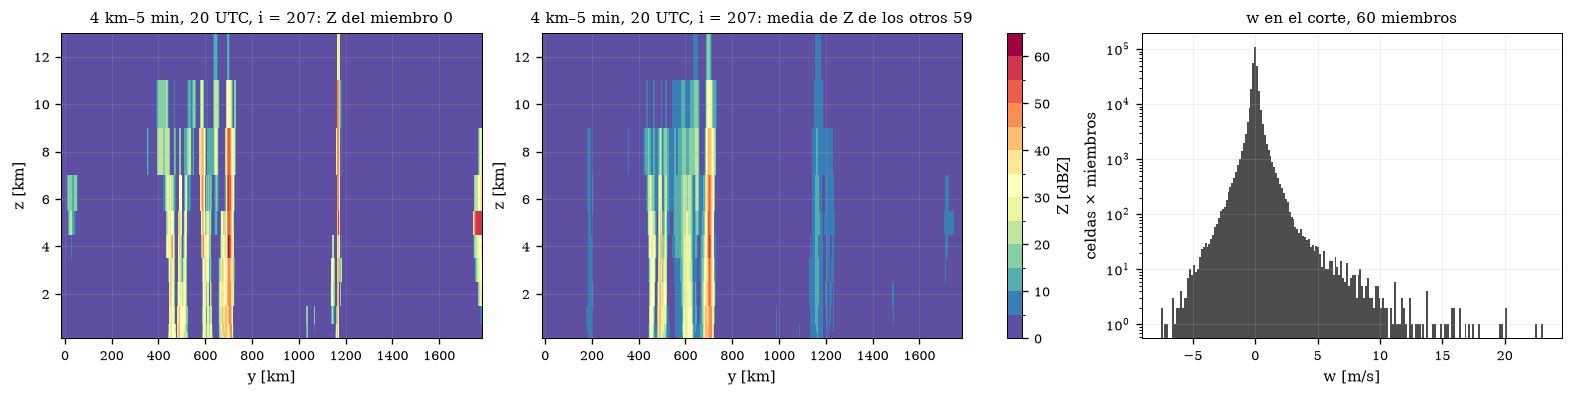

In [7]:
y_km = pos[I_SLAB, :, 0, 1]
others = np.delete(np.arange(Z.shape[2]), TM)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), constrained_layout=True)
for a, fld, t in ((ax[0], Z[:, :, TM], f"Z del miembro {TM}"),
                  (ax[1], Z[:, :, others].mean(axis=2), "media de Z de los otros 59")):
    m = a.pcolormesh(y_km, z_lev, fld.T, cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM, shading="nearest")
    a.set(xlabel="y [km]", ylabel="z [km]", title=f"{nb.DS_LABEL[DS]}, {HOUR} UTC, i = {I_SLAB}: {t}")
fig.colorbar(m, ax=ax[:2], label="Z [dBZ]")
w = slab[..., nb.VI["w"]]
ax[2].hist(w[np.isfinite(w)].ravel(), bins=200, log=True, color="0.3")
ax[2].set(xlabel="w [m/s]", ylabel="celdas × miembros", title="w en el corte, 60 miembros")
plt.show()

## 2 · Experimentos de observación única

**Ruta:** `data/WS_{ds}_sweep_{hh}00_LOC0.1_ALLMEM/WS_{ds}_sweep_{hh}00_LOC0.1_ALLMEM_sweep_Ne059_tm{tm:02d}.npz`, `nb.sweep_files(tag, tm)`. Un archivo por (dataset, hora, miembro verdad): 60 por carpeta, 12 carpetas para A, B y C. Al lado, `…_config.yaml` con la configuración de la corrida (`nb.run_config(tag)`): R = 5 dBZ², piso de 0 dBZ, localización de 0,1 km, una celda de cada 10 (`stride`), esquemas TEnKF con $N_t$ = 1..10 y AOEI.

**Una fila** es un experimento: una observación en una celda `(i, j, k)` asimilada con un esquema. Las celdas son las que pasan el control de calidad (algún miembro del prior con Z > 0 dBZ); cada celda aparece una vez por esquema, 11 filas por celda. Todas las columnas son vectores de la misma longitud.

Columnas de identidad: `i, j, k`, `x_km, y_km, z_km`, `method` (`TEnKF` o `AOEI`), `ntemp` ($N_t$), `alpha_s`, `lx_km, ly_km, lz_km`.

Observación: `yo` = observación con ruido gaussiano de varianza R, con piso en 0 dBZ; `yo_clean` = $h(\mathbf{x}_\mathrm{true})$ sin ruido, la verdad de la reflectividad. `hxf_mean_obs`, `hxa_mean_obs` = media de $h(\mathbf{x})$ del prior y del posterior [dBZ]; `dep_b = yo − hxf_mean_obs` (la innovación $d$), `dep_a`, `inc_obs`. `n_active_f_point` = miembros del prior con Z > 0 dBZ en la celda ($N_{Z>0}$).

Las métricas siguen la gramática `{métrica}_{etapa}_{reducción}_{variable}`:

- métrica: `rmse`, `crps`, `bias`, `spread`, `skew`, `kurt`; además `mean_{f,a}_point_{v}` y `truth_point_{v}`;
- etapa: `f` (prior) o `a` (posterior);
- reducción: `point` = en la celda observada; `w` = media pesada por la localización; `u` = media en la zona de corte;
- variable: `obs` (Z, en dBZ) o una de las 8 de estado, en sus unidades crudas.

En la reducción `point`, `rmse` es $|e|$ = |media − verdad| de un experimento, y `crps` es el CRPS empírico de los 59 miembros contra la verdad. Existe `crps_{f,a}_point_{v}` para Z y para cada una de las 8 variables de estado; no hay columna para $q_g+q_r+q_s$.

In [8]:
TAG_S = f"WS_{DS}_sweep_{HOUR}00_LOC0.1_ALLMEM"
F_S = nb.sweep_files(TAG_S, [TM])[0]
K_S = describe_npz(F_S, show=False)
print("\nmétricas por (métrica, reducción) × variable; cada celda dice qué etapas existen:")
display(grammar(K_S.clave, r"^(?P<metrica>rmse|crps|bias|spread|skew|kurt|mean)_(?P<etapa>f|a)_"
                           r"(?P<reduccion>point|w|u)_(?P<variable>\w+)$",
                ["metrica", "reduccion"], ["variable"]))
rx = re.compile(r"^(rmse|crps|bias|spread|skew|kurt|mean)_(f|a)_(point|w|u)_\w+$|^truth_point_\w+$")
print("otras claves:", ", ".join(k for k in K_S.clave if not rx.match(k)))
print("verdad del estado:", ", ".join(k for k in K_S.clave if k.startswith("truth_point_")))

data/WS_A_sweep_2000_LOC0.1_ALLMEM/WS_A_sweep_2000_LOC0.1_ALLMEM_sweep_Ne059_tm00.npz   62.1 MB en disco, 362 claves

métricas por (métrica, reducción) × variable; cada celda dice qué etapas existen:


variable             P    T  obs   qg   qr   qs    u    v    w
metrica reduccion                                             
bias    point        ·    ·  a,f    ·    ·    ·    ·    ·    ·
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
crps    point      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
kurt    point      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
mean    point      a,f  a,f    ·  a,f  a,f  a,f  a,f  a,f  a,f
rmse    point      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
skew    point      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
spread  point      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        u          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        w          a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f

otras claves: var_names, i, j, k, x_km, y_km, z_km, yo, yo_clean, method, ntemp, alpha_s, lx_km, ly_km, lz_km, loc_weights_sum, n_updated, hxf_mean_obs, hxa_mean_obs, dep_b, dep_a, inc_obs, spread_f_obs, spread_a_obs, n_active_f_point, n_active_f_w, n_active_f_u, hx_dbz_local_mean_w, hx_dbz_local_mean_u, precip_fraction_f
verdad del estado: truth_point_qg, truth_point_qr, truth_point_qs, truth_point_T, truth_point_P, truth_point_u, truth_point_v, truth_point_w


In [9]:
COLS_S = ["i", "j", "k", "x_km", "y_km", "z_km", "yo", "yo_clean", "method", "ntemp", "alpha_s",
          "lx_km", "ly_km", "lz_km", "hxf_mean_obs", "hxa_mean_obs", "dep_b", "n_active_f_point",
          "rmse_f_point_obs", "rmse_a_point_obs", "crps_f_point_obs", "crps_a_point_obs",
          "mean_f_point_w", "mean_a_point_w", "truth_point_w", "crps_f_point_w", "crps_a_point_w"]
S = nb.load_sweep(F_S, columns=COLS_S, verbose=False)
print(f"{len(S):,} filas;  filas por esquema:")
display(S.groupby(["method", "ntemp"]).size().rename("filas").to_frame().T)
display(S.head(3))
# Lo que dice el texto de arriba, comprobado en el archivo
t1 = S[(S.method == "TEnKF") & (S.ntemp == 1)]
print("dep_b = yo − hxf_mean_obs:", np.allclose(S.dep_b, S.yo - S.hxf_mean_obs))
print("rmse_f_point_obs = |hxf_mean_obs − yo_clean|:",
      np.allclose(S.rmse_f_point_obs, np.abs(S.hxf_mean_obs - S.yo_clean)))
print("rmse_*_point de w = |mean − truth|: no se guarda para el estado; se arma con mean_* y truth_point_*")
print(f"N_Z>0 entre {t1.n_active_f_point.min():.0f} y {t1.n_active_f_point.max():.0f}")
print(nb.run_config(TAG_S)["sweep"])

103,862 filas;  filas por esquema:


method  AOEI TEnKF                                                      
ntemp     1     1     2     3     4     5     6     7     8     9     10
filas   9442  9442  9442  9442  9442  9442  9442  9442  9442  9442  9442

,i,j,k,x_km,y_km,z_km,yo,yo_clean,method,ntemp,alpha_s,lx_km,ly_km,lz_km,hxf_mean_obs,hxa_mean_obs,dep_b,n_active_f_point,rmse_f_point_obs,rmse_a_point_obs,crps_f_point_obs,crps_a_point_obs,mean_f_point_w,mean_a_point_w,truth_point_w,crps_f_point_w,crps_a_point_w
0,30,450,8,214.453369,1785.719849,8.0,3.399626,0.0,TEnKF,1,1.0,0.1,0.1,0.1,1.511355,7.576249,1.888272,5.0,1.511355,7.576249,0.094839,6.837960,-0.026513,-0.005785,0.535156,0.424531,0.406024
1,30,450,8,214.453369,1785.719849,8.0,3.399626,0.0,TEnKF,2,1.0,0.1,0.1,0.1,1.511355,4.556446,1.888272,5.0,1.511355,4.556446,0.094839,3.616271,-0.026513,-0.018008,0.535156,0.424531,0.418561
2,30,450,8,214.453369,1785.719849,8.0,3.399626,0.0,TEnKF,3,1.0,0.1,0.1,0.1,1.511355,1.121770,1.888272,5.0,1.511355,1.121770,0.094839,0.067451,-0.026513,-0.030442,0.535156,0.424531,0.431067


dep_b = yo − hxf_mean_obs: True
rmse_f_point_obs = |hxf_mean_obs − yo_clean|: True
rmse_*_point de w = |mean − truth|: no se guarda para el estado; se arma con mean_* y truth_point_*
N_Z>0 entre 1 y 59
{'truth_members': {'start': 0, 'stop': 59, 'step': 1}, 'prior_size': 60, 'obs_points': {'mode': 'sweep'}, 'stride': 10, 'methods': ['TEnKF', 'AOEI'], 'ntemp': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'alpha_s': 1.0, 'loc_x': 0.1, 'loc_y': 0.1, 'loc_z': 0.1}


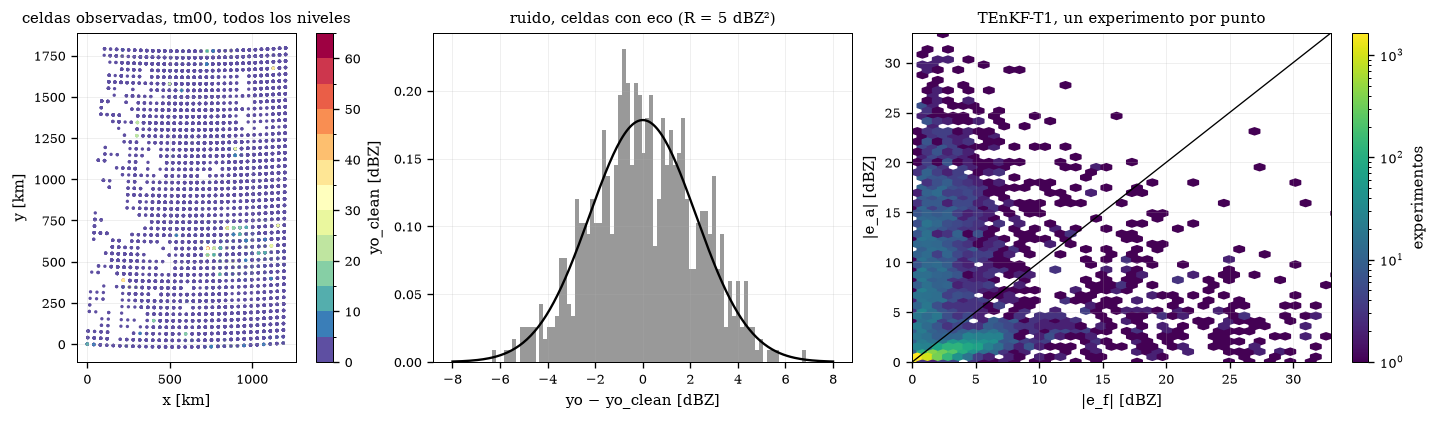

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), constrained_layout=True)
m = ax[0].scatter(t1.x_km, t1.y_km, c=t1.yo_clean, s=1, cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM)
fig.colorbar(m, ax=ax[0], label="yo_clean [dBZ]")
ax[0].set(xlabel="x [km]", ylabel="y [km]", aspect="equal",
          title=f"celdas observadas, tm{TM:02d}, todos los niveles")
R = float(nb.run_config(TAG_S)["obs"]["obs_error_var"])
eco = t1.yo_clean > 0
noise = (t1.yo - t1.yo_clean)[eco & (t1.yo > 0)]
xs = np.linspace(-8, 8, 200)
ax[1].hist(noise, bins=80, density=True, color="0.6")
ax[1].plot(xs, np.exp(-xs ** 2 / (2 * R)) / np.sqrt(2 * np.pi * R), "k")
ax[1].set(xlabel="yo − yo_clean [dBZ]", title=f"ruido, celdas con eco (R = {R:g} dBZ²)")
hb = ax[2].hexbin(t1.rmse_f_point_obs, t1.rmse_a_point_obs, gridsize=60, bins="log", mincnt=1)
lim = [0, np.nanpercentile(t1.rmse_f_point_obs, 99.5)]
ax[2].plot(lim, lim, "k", lw=0.8)
ax[2].set(xlim=lim, ylim=lim, xlabel="|e_f| [dBZ]", ylabel="|e_a| [dBZ]", title="TEnKF-T1, un experimento por punto")
fig.colorbar(hb, ax=ax[2], label="experimentos")
plt.show()

## 3 · Experimentos de observaciones múltiples

**Rutas**, en `data/WS_{ds}_multiobs_{hh}00_LOC2.0_REF/`:

- `…_multi_obs_{método}_Nt{nt:02d}_as1.0_Lx2.0Ly2.0Lz2.0_Ne059_tm{tm:02d}.npz`: una asimilación, por (dataset, hora, esquema, miembro verdad). Esquemas TEnKF $N_t$ = 1..5 y AOEI; 12 miembros verdad (0, 2, 17, 19, 20, 22, 28, 33, 39, 43, 54, 59, de la config). 72 archivos por carpeta.
- `…_multi_obs_ref_Ne059_tm{tm:02d}.npz`: lo que no depende del esquema, uno por miembro verdad.

Se asimilan a la vez todas las celdas que pasan el control (`stride` 1), con localización de 2 km.

**Archivo de esquema:**

- Campos 3D `(nx, ny, nz)` de la reflectividad [dBZ]: `hxf_mean_field`, `hxa_mean_field`, `truth_hx_field`; `err_hxf_field` = `hxf_mean_field − truth_hx_field`; `residual_field` = `hxa_mean_field − truth_hx_field`; `spread_{f,a}_ref_field`, `crps_{f,a}_ref_field` [dBZ]; `skew_*`, `kurt_*` (adimensionales); `n_active_f_field` ($N_{Z>0}$). Un elemento = una celda del dominio, la unidad del experimento en N4.
- Escalares por dominio: `{métrica}_{f,a}_{dominio}_{variable}` y su conteo `n_{métrica}_…`, con dominio `global`, `storm` (columnas con máximo de la verdad ≥ 20 dBZ) u `obs` (celdas observadas), y variable `ref` (Z) o una de estado. Son sobre el dominio entero, con las celdas que la LETKF no alcanzó adentro.
- Conteos de mejora del runner: `n_skill_…`, `n_improved_…`, `n_degraded_…`, `skill_mean_…`, `skill_median_…`. Para las variables de estado se clasificaron sin banda de empate, así que no se usan.
- Censura de hidrometeoros (`clamp_*`), masas (`mass_*`), control de calidad (`qc_*`), identidad (`dataset_id`, …).

**Archivo `ref`:** `truth` y `xf_mean`, `(nx, ny, nz, 8)`, la verdad y la media del prior del estado; `truth_hx_field` (y su alias viejo `truth_hx`), `hxf_mean_field`, `hx_of_xfmean_field` = $h(\overline{\mathbf{x}}_f)$; y la lista de observaciones: `ix, iy, iz`, `yo`, `yo_clean`, una entrada por observación.

In [11]:
TAG_M = f"WS_{DS}_multiobs_{HOUR}00_LOC2.0_REF"
F_M = sorted(nb.run_dir(TAG_M).glob(f"{TAG_M}_multi_obs_TEnKF_Nt02_*_tm{TM:02d}.npz"))[0]
F_R = nb.run_dir(TAG_M) / f"{TAG_M}_multi_obs_ref_Ne059_tm{TM:02d}.npz"
K_M = describe_npz(F_M, show=False)
print("campos 3D:")
display(K_M[K_M.forma.str.count(",") == 2])
print("escalares por dominio; cada celda dice qué etapas existen:")
display(grammar(K_M.clave, r"^(?:n_)?(?P<metrica>rmse|bias|spread|crps|skew|kurt)_(?P<etapa>f|a)_"
                           r"(?P<dominio>global|storm|obs)_(?P<variable>\w+)$",
                ["metrica", "dominio"], ["variable"]))
g = K_M.clave.str.extract(r"^([a-z]+)_")[0].value_counts()
print("claves por prefijo:", dict(g))

data/WS_A_multiobs_2000_LOC2.0_REF/WS_A_multiobs_2000_LOC2.0_REF_multi_obs_TEnKF_Nt02_as1.0_Lx2.0Ly2.0Lz2.0_Ne059_tm00.npz   40.7 MB en disco, 956 claves
campos 3D:


,clave,forma,dtype,tamaño
88,hxf_mean_field,"(307, 451, 11)",float32,6.1 MB
89,hxa_mean_field,"(307, 451, 11)",float32,6.1 MB
90,truth_hx_field,"(307, 451, 11)",float32,6.1 MB
91,err_hxf_field,"(307, 451, 11)",float32,6.1 MB
92,residual_field,"(307, 451, 11)",float32,6.1 MB
93,spread_f_ref_field,"(307, 451, 11)",float32,6.1 MB
94,skew_f_ref_field,"(307, 451, 11)",float32,6.1 MB
95,kurt_f_ref_field,"(307, 451, 11)",float32,6.1 MB
96,crps_f_ref_field,"(307, 451, 11)",float32,6.1 MB
97,n_active_f_field,"(307, 451, 11)",int16,3.0 MB


escalares por dominio; cada celda dice qué etapas existen:


variable           P    T   qg   qr   qs  ref    u    v    w
metrica dominio                                             
bias    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
crps    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
kurt    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
rmse    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
skew    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
spread  global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f

claves por prefijo: {'n': np.int64(424), 'skill': np.int64(108), 'spread': np.int64(56), 'skew': np.int64(56), 'kurt': np.int64(56), 'crps': np.int64(56), 'rmse': np.int64(54), 'bias': np.int64(54), 'mass': np.int64(45), 'clamp': np.int64(10), 'qc': np.int64(7), 'frac': np.int64(4), 'truth': np.int64(2), 'config': np.int64(2), 'alpha': np.int64(1), 'lx': np.int64(1), 'ly': np.int64(1), 'lz': np.int64(1), 'var': np.int64(1), 'ref': np.int64(1), 'storage': np.int64(1), 'store': np.int64(1), 'dataset': np.int64(1), 'da': np.int64(1), 'dx': np.int64(1), 'echo': np.int64(1), 'hxf': np.int64(1), 'hxa': np.int64(1), 'err': np.int64(1), 'residual': np.int64(1), 'storm': np.int64(1)}


In [12]:
describe_npz(F_R)
sc = scalars_npz(F_M)
print({k: sc[k] for k in ("method", "ntemp", "truth_member", "n_obs_final", "n_cells_global",
                          "n_touched_global", "rmse_f_global_ref", "rmse_a_global_ref",
                          "n_rmse_f_global_ref", "storm_thresh_dbz", "clamp_mode")})
with np.load(F_M) as z, np.load(F_R) as r:
    thx, ef, ea = r["truth_hx_field"], z["err_hxf_field"], z["residual_field"]
    print("err_hxf_field = hxf_mean_field − truth_hx_field:",
          np.allclose(ef, z["hxf_mean_field"] - z["truth_hx_field"], equal_nan=True))
    print("truth_hx_field del ref = el del esquema:", np.array_equal(thx, z["truth_hx_field"], equal_nan=True))
    yo, yc = r["yo"], r["yo_clean"]
    print(f"{yo.size:,} observaciones de {thx.size:,} celdas")
print(nb.run_config(TAG_M)["sweep"])

data/WS_A_multiobs_2000_LOC2.0_REF/WS_A_multiobs_2000_LOC2.0_REF_multi_obs_ref_Ne059_tm00.npz   76.5 MB en disco, 32 claves


,clave,forma,dtype,tamaño
0,truth,"(307, 451, 11, 8)",float32,48.7 MB
1,xf_mean,"(307, 451, 11, 8)",float32,48.7 MB
2,truth_hx,"(307, 451, 11)",float32,6.1 MB
3,truth_hx_field,"(307, 451, 11)",float32,6.1 MB
4,hxf_mean_field,"(307, 451, 11)",float32,6.1 MB
5,hx_of_xfmean_field,"(307, 451, 11)",float32,6.1 MB
6,yo,"(920481,)",float32,3.7 MB
7,yo_clean,"(920481,)",float32,3.7 MB
8,ix,"(920481,)",int32,3.7 MB
9,iy,"(920481,)",int32,3.7 MB


{'method': 'TEnKF', 'ntemp': 2, 'truth_member': 0, 'n_obs_final': 920481, 'n_cells_global': 1523027, 'n_touched_global': 1378625, 'rmse_f_global_ref': 4.409363341379074, 'rmse_a_global_ref': 2.808273519123455, 'n_rmse_f_global_ref': 1523027, 'storm_thresh_dbz': 20.0, 'clamp_mode': 'per_step'}
err_hxf_field = hxf_mean_field − truth_hx_field: True
truth_hx_field del ref = el del esquema: True
920,481 observaciones de 1,523,027 celdas
{'truth_members': [0, 2, 17, 19, 20, 22, 28, 33, 39, 43, 54, 59], 'prior_size': 60, 'obs_points': {'mode': 'multi_obs'}, 'stride': 1, 'methods': ['TEnKF', 'AOEI'], 'ntemp': [1, 2, 3, 4, 5], 'alpha_s': 1.0, 'loc_x': 2.0, 'loc_y': 2.0, 'loc_z': 2.0}


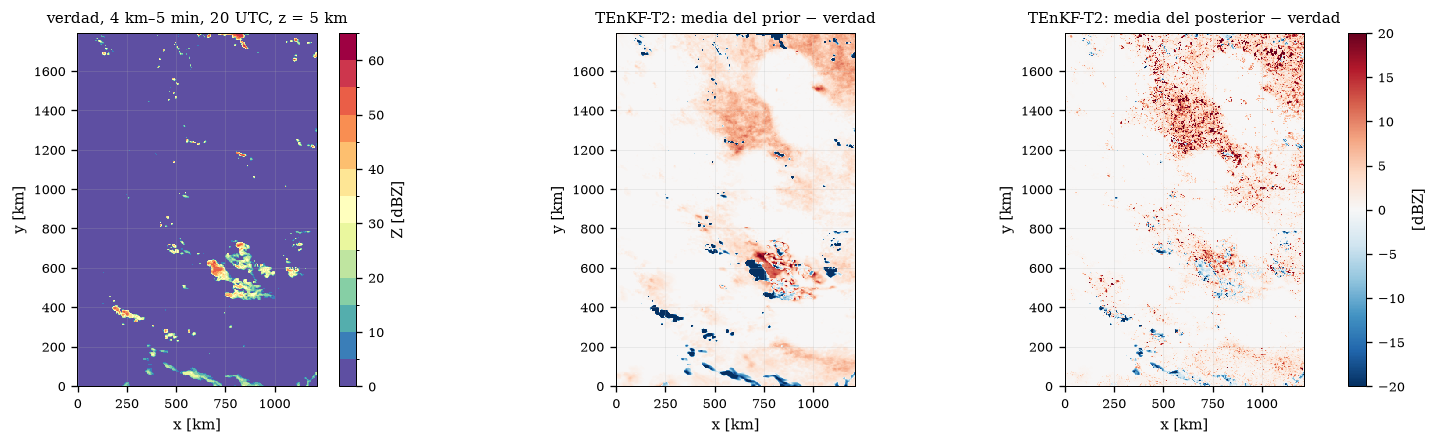

In [13]:
x_km, y_km = pos[:, 0, 0, 0], pos[0, :, 0, 1]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
m0 = ax[0].pcolormesh(x_km, y_km, thx[:, :, K_MAP].T, cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM, shading="nearest")
fig.colorbar(m0, ax=ax[0], label="Z [dBZ]")
vmax = 20
for a, fld, t in ((ax[1], ef, "media del prior − verdad"), (ax[2], ea, "media del posterior − verdad")):
    m = a.pcolormesh(x_km, y_km, fld[:, :, K_MAP].T, cmap=nb.CMAP_DIV, vmin=-vmax, vmax=vmax, shading="nearest")
    a.set_title(f"TEnKF-T2: {t}")
fig.colorbar(m, ax=ax[1:], label="[dBZ]")
ax[0].set_title(f"verdad, {nb.DS_LABEL[DS]}, {HOUR} UTC, z = {z_lev[K_MAP]:g} km")
for a in ax:
    a.set(xlabel="x [km]", ylabel="y [km]", aspect="equal")
plt.show()

## 4 · Intermedios de `data/derived/`

Los escribe la sección 0 de cada notebook en `data/derived/N2/`, `N3/`, `N3s/` y `N4/`; las celdas de análisis y de figuras leen solo esto. Con `REBUILD = False` y los archivos presentes, la sección 0 solo los carga.

N3 y N4 guardan **sumas** por población, no estadísticos, para poder juntar cualquier conjunto de filas (un dataset, un bin, un miembro verdad). Con `n` experimentos: `se2_{f,a}` = $\sum e^2$, `sae_{f,a}` = $\sum |e|$, `scrps_{f,a}` = $\sum \mathrm{CRPS}$, `ssp_{f,a}` = $\sum \sigma$ y `ssp2_{f,a}` = $\sum \sigma^2$ (la dispersión del ensamble en la celda), `n_change` (los que cambian: $\big||e_f| - |e_a|\big|$ mayor que la tolerancia de la variable, `nb.TOL`) y `n_imp` (los que mejoran). De ahí $\mathrm{RMSE} = \sqrt{\sum e^2 / n}$, $\mathrm{CRPS} = \sum \mathrm{CRPS} / n$, $\mathrm{SS}_\mathrm{RMSE} = 1 - \mathrm{RMSE}_a/\mathrm{RMSE}_f$, $\mathrm{SS}_\mathrm{CRPS} = 1 - \mathrm{CRPS}_a/\mathrm{CRPS}_f$ y la fracción que mejora $F$ = `n_imp / n_change`.

### 4.1 · N2

**`N2/N2_maps.npz`** (`build`, sección 0 de N2). Mapas por columna de la reflectividad del prior, con los 59 miembros que quedan sin el miembro verdad 0. Claves `{ds}/{hh}/{campo}`, (nx, ny), un elemento = una columna `(i, j)`:

- `colmax_dbz_mean`: máximo en la columna de la media del ensamble [dBZ];
- `colmax_dbz_membermax`: máximo en la columna y entre miembros [dBZ];
- `colmax_dbz_spread` [dBZ] y `colmean_dbz_spread_echo`: media sobre los niveles con eco [dBZ];
- `n_levels_echo`: niveles con eco; `colmax_n_active`: máximo de $N_{Z>0}$;
- `colmax_skew_dbz_kKK`, `colmax_kurt_dbz_kKK`: asimetría y exceso de curtosis entre miembros (adimensionales), con signo, en el nivel de máximo |·| entre los que tienen al menos KK miembros con eco; `n_levels_used_kKK`.

Por dataset: `{ds}/lats`, `{ds}/lons` (ny, nx) [grados], `{ds}/z_km`, `{ds}/dx_km`, `{ds}/dy_km`, `{ds}/cell_km2`. Globales: `truth_member`, `min_dbz`, `k_list`.

data/derived/N2/N2_maps.npz   73.6 MB en disco, 201 claves


ds,A,B,C
campo,,,
colmax_dbz_mean,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_dbz_membermax,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_dbz_spread,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_dbz_k01,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_dbz_k05,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_dbz_k10,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_n_active,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_skew_dbz_k01,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_skew_dbz_k05,"18,19,20,21","18,19,20,21","18,19,20,21"


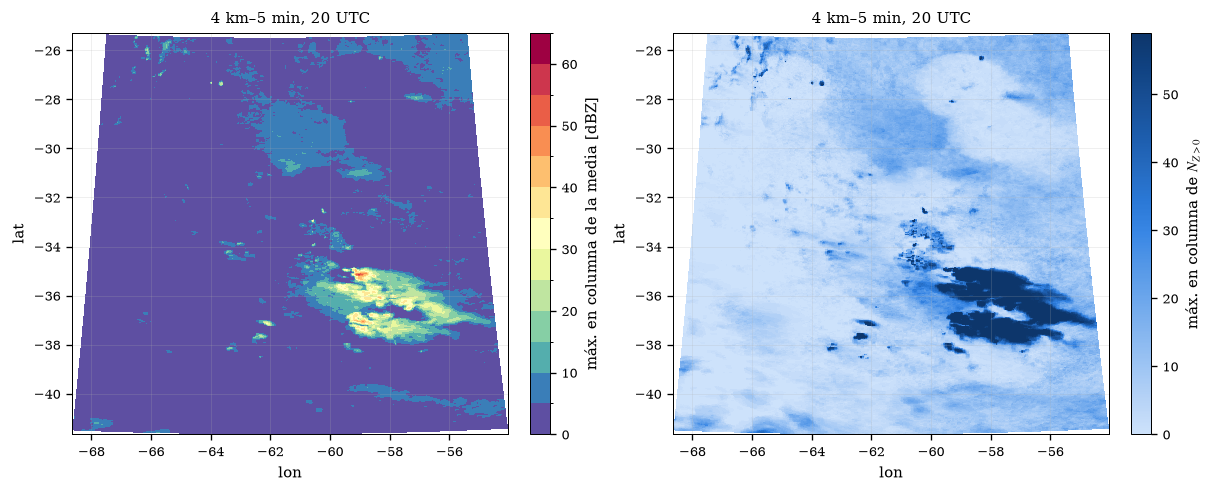

In [14]:
F = DERIVED / "N2" / "N2_maps.npz"
K = describe_npz(F, show=False)
display(grammar(K.clave, r"^(?P<ds>[ABCD])/(?P<hh>\d\d)/(?P<campo>.+)$", ["campo"], ["ds"]))
M2 = np.load(F)
lo, la = M2[f"{DS}/lons"], M2[f"{DS}/lats"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
m = ax[0].pcolormesh(lo, la, M2[f"{DS}/{HOUR}/colmax_dbz_mean"].T, cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM)
fig.colorbar(m, ax=ax[0], label="máx. en columna de la media [dBZ]")
m = ax[1].pcolormesh(lo, la, M2[f"{DS}/{HOUR}/colmax_n_active"].T, cmap=nb.CMAP_SEQ, vmin=0, vmax=59)
fig.colorbar(m, ax=ax[1], label="máx. en columna de $N_{Z>0}$")
for a in ax:
    a.set(xlabel="lon", ylabel="lat", title=f"{nb.DS_LABEL[DS]}, {HOUR} UTC")
plt.show()

**`N2/N2_state.npz`** (`build`, sección 0 de N2). Lo mismo para las variables de estado, mismas claves `{ds}/{hh}/{campo}`, (nx, ny):

- `colmax_mean_qtot`, `colmax_spread_qtot` [g/kg], de $q_g+q_r+q_s$;
- `w_mean_at_absmax`: la media de w, con signo, en el nivel de máximo |w| [m/s]; `colmax_spread_w` [m/s];
- `colmax_skew_{qtot,w}_kKK`, `colmax_kurt_{qtot,w}_kKK`, `n_levels_used_{qtot,w}_kKK`. Un miembro "carga" $q$ si $q > 10^{-6}$ kg/kg y w si $|w| > 0{,}01$ m/s.

data/derived/N2/N2_state.npz   154.4 MB en disco, 264 claves


ds,A,B,C
campo,,,
colmax_kurt_qtot_k01,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_qtot_k05,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_qtot_k10,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_w_k01,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_w_k05,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_kurt_w_k10,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_mean_qtot,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_skew_qtot_k01,"18,19,20,21","18,19,20,21","18,19,20,21"
colmax_skew_qtot_k05,"18,19,20,21","18,19,20,21","18,19,20,21"


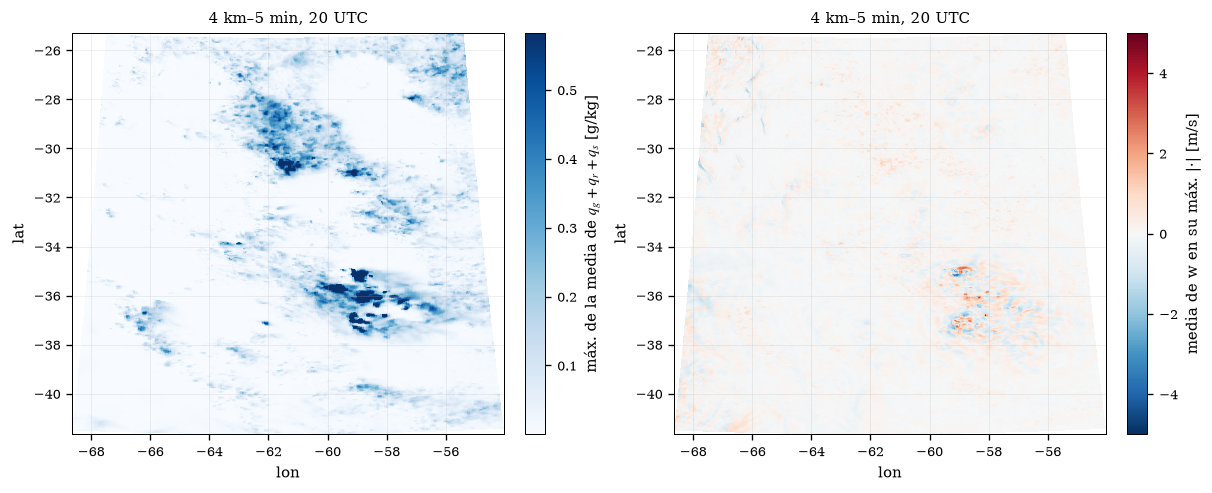

In [15]:
F = DERIVED / "N2" / "N2_state.npz"
K = describe_npz(F, show=False)
display(grammar(K.clave, r"^(?P<ds>[ABCD])/(?P<hh>\d\d)/(?P<campo>.+)$", ["campo"], ["ds"]))
S2 = np.load(F)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
q = S2[f"{DS}/{HOUR}/colmax_mean_qtot"]
m = ax[0].pcolormesh(lo, la, q.T, cmap="Blues", vmax=np.nanpercentile(q, 99.5))
fig.colorbar(m, ax=ax[0], label="máx. de la media de $q_g+q_r+q_s$ [g/kg]")
m = ax[1].pcolormesh(lo, la, S2[f"{DS}/{HOUR}/w_mean_at_absmax"].T, cmap=nb.CMAP_DIV, vmin=-5, vmax=5)
fig.colorbar(m, ax=ax[1], label="media de w en su máx. |·| [m/s]")
for a in ax:
    a.set(xlabel="lon", ylabel="lat", title=f"{nb.DS_LABEL[DS]}, {HOUR} UTC")
plt.show()

**`N2/N2_section.npz`** (`build`, sección 0 de N2). El corte vertical x–z del dataset A en la fila `J0` = 180: `{hh}/dbz_mean` (nx, nz) [dBZ] y `{hh}/mean_w` (nx, nz) [m/s], medias del ensamble; `cut_lat`, `cut_lon`, `x_km` (nx,); `z_km` (nz,); `J0`; `dataset`.

data/derived/N2/N2_section.npz   0.1 MB en disco, 14 claves


,clave,forma,dtype,tamaño
0,18/dbz_mean,"(307, 11)",float32,0.0 MB
1,18/mean_w,"(307, 11)",float32,0.0 MB
2,19/dbz_mean,"(307, 11)",float32,0.0 MB
3,19/mean_w,"(307, 11)",float32,0.0 MB
4,20/dbz_mean,"(307, 11)",float32,0.0 MB
5,20/mean_w,"(307, 11)",float32,0.0 MB
6,21/dbz_mean,"(307, 11)",float32,0.0 MB
7,21/mean_w,"(307, 11)",float32,0.0 MB
8,cut_lat,"(307,)",float32,0.0 MB
9,cut_lon,"(307,)",float32,0.0 MB


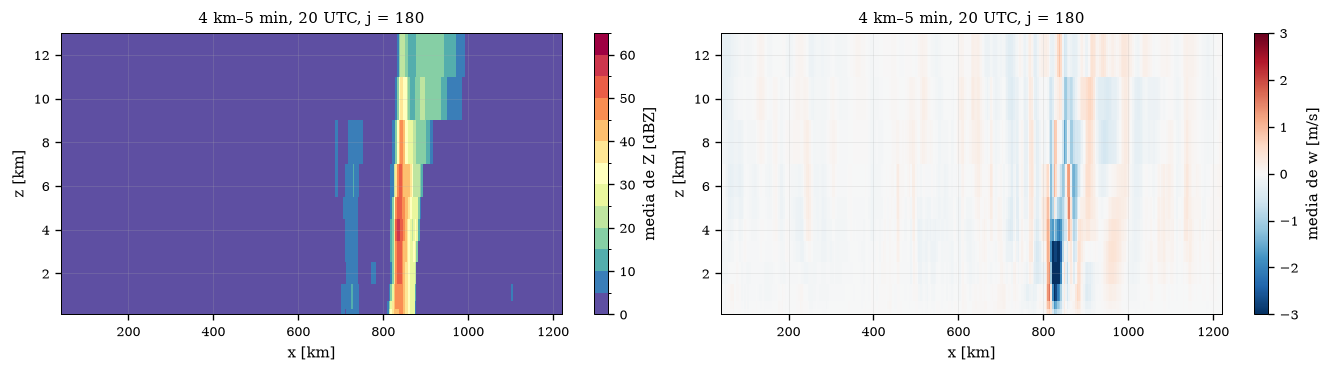

In [16]:
F = DERIVED / "N2" / "N2_section.npz"
describe_npz(F)
C2 = np.load(F)
fig, ax = plt.subplots(1, 2, figsize=(11, 3), constrained_layout=True)
m = ax[0].pcolormesh(C2["x_km"], C2["z_km"], C2[f"{HOUR}/dbz_mean"].T, cmap=nb.DBZ_CMAP, norm=nb.DBZ_NORM, shading="nearest")
fig.colorbar(m, ax=ax[0], label="media de Z [dBZ]")
m = ax[1].pcolormesh(C2["x_km"], C2["z_km"], C2[f"{HOUR}/mean_w"].T, cmap=nb.CMAP_DIV, vmin=-3, vmax=3, shading="nearest")
fig.colorbar(m, ax=ax[1], label="media de w [m/s]")
for a in ax:
    a.set(xlabel="x [km]", ylabel="z [km]", title=f"{nb.DS_LABEL[str(C2['dataset'])]}, {HOUR} UTC, j = {int(C2['J0'])}")
plt.show()

**`N2/N2_hist.csv`** (`build`, sección 0 de N2). Una fila = un bin de 0,25 dBZ con cuenta no nula del histograma de Z de los 59 miembros en todas las celdas, por (dataset, hora). `bin_left`, `bin_right` [dBZ], `count` (celdas × miembros). Lo que pasa de 80 dBZ se cuenta en `N2_scalars.hist_n_above`.

data/derived/N2/N2_hist.csv   0.1 MB, 3,227 filas × 5 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.00,2.100000e+01,18
bin_left,float64,277,0.00,6.900000e+01,0.0
bin_right,float64,277,0.25,6.925000e+01,0.25
count,int64,2939,1.00,3.063856e+08,86252224


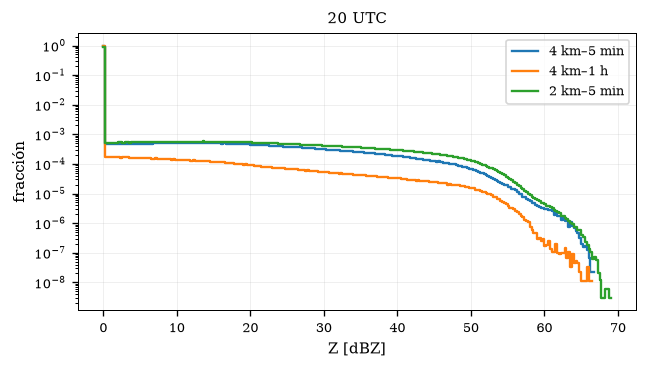

In [17]:
H2 = describe_csv(DERIVED / "N2" / "N2_hist.csv")
fig, ax = plt.subplots(figsize=(6, 3))
for ds, g in H2[H2.hour == int(HOUR)].groupby("dataset"):
    ax.step(g.bin_left, g["count"] / g["count"].sum(), where="post", label=nb.DS_LABEL.get(ds, ds))
ax.set(yscale="log", xlabel="Z [dBZ]", ylabel="fracción", title=f"{HOUR} UTC")
ax.legend()
plt.show()

**`N2/N2_profiles.csv`** (`build`, sección 0 de N2). Una fila = (dataset, hora, nivel). `z_km`; `n_cells` (celdas del nivel), `n_echo` (celdas con $N_{Z>0} > 0$), `n_nan`; sobre las celdas con eco: `spread_mean`, `spread_median` [dBZ], `n_active_mean`, `n_active_median` [miembros], `abs_skew_*`, `abs_kurt_*` (adimensionales).

data/derived/N2/N2_profiles.csv   0.0 MB, 132 filas × 14 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,21.000000,18
z_km,float64,11,0.250000,12.000000,0.25
n_cells,int64,2,138457.000000,501084.000000,138457
n_echo,int64,132,8213.000000,332879.000000,83105
n_nan,int64,1,0.000000,0.000000,0
spread_mean,float64,132,2.503569,8.167125,5.605919
spread_median,float64,132,1.809027,7.709129,5.180377
n_active_mean,float64,132,1.723609,11.538784,5.681042
n_active_median,float64,7,1.000000,7.000000,4.0


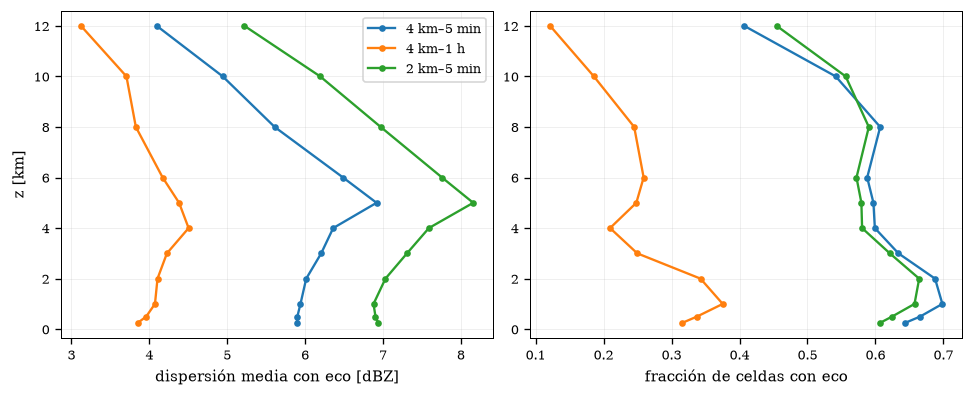

In [18]:
P2 = describe_csv(DERIVED / "N2" / "N2_profiles.csv")
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2), constrained_layout=True)
for ds, g in P2[P2.hour == int(HOUR)].groupby("dataset"):
    ax[0].plot(g.spread_mean, g.z_km, "-o", ms=3, label=nb.DS_LABEL.get(ds, ds))
    ax[1].plot(g.n_echo / g.n_cells, g.z_km, "-o", ms=3)
ax[0].set(xlabel="dispersión media con eco [dBZ]", ylabel="z [km]")
ax[1].set(xlabel="fracción de celdas con eco")
ax[0].legend()
plt.show()

**`N2/N2_scalars.csv`** (`build`, sección 0 de N2). Una fila = (dataset, hora). Escalares para el texto: `Ne`, `cell_km2`; `peak_mean`, `peak_max` [dBZ]; áreas sobre 20 dBZ, en celdas (`area_gt20_*`) y km² (`km2_gt20_*`); `echo_frac`, `echo_cols` (columnas con algún miembro con eco); `med_n_active`, `med_spread` [dBZ]; los totales del histograma; el techo de asimetría y curtosis de 59 miembros (`ceil_*`) y el porcentaje de columnas en el techo; medianas de |asimetría| dentro y fuera del eco (`med_abs_skew_in/out`, umbral 15 dBZ).

data/derived/N2/N2_scalars.csv   0.0 MB, 12 filas × 29 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,1.800000e+01,2.100000e+01,18
Ne,int64,1,6.000000e+01,6.000000e+01,60
cell_km2,float64,2,3.949237e+00,1.579452e+01,15.794517
k_fig,int64,1,1.000000e+00,1.000000e+00,1
k_tab,int64,1,5.000000e+00,5.000000e+00,5
peak_mean,float64,12,2.949008e+01,5.538246e+01,43.451672
peak_max,float64,12,6.570763e+01,6.917842e+01,66.822617
area_gt20_mean,int64,12,1.600000e+01,1.169200e+04,959
area_gt20_max,int64,12,3.869100e+04,3.332860e+05,83833


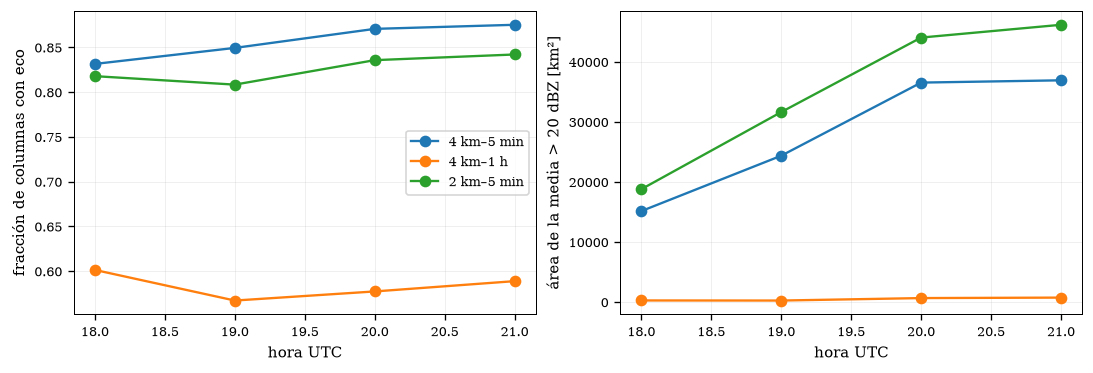

In [19]:
SC2 = describe_csv(DERIVED / "N2" / "N2_scalars.csv")
fig, ax = plt.subplots(1, 2, figsize=(9, 3), constrained_layout=True)
for ds, g in SC2.groupby("dataset"):
    ax[0].plot(g.hour, g.echo_frac, "-o", label=nb.DS_LABEL.get(ds, ds))
    ax[1].plot(g.hour, g.km2_gt20_mean, "-o")
ax[0].set(xlabel="hora UTC", ylabel="fracción de columnas con eco")
ax[1].set(xlabel="hora UTC", ylabel="área de la media > 20 dBZ [km²]")
ax[0].legend()
plt.show()

**`N2/N2_departures.csv`** (`build`, sección 0 de N2). Una fila = (dataset, miembro, rama), las cuatro horas sumadas. El *departure* de un miembro es $d_m = Z_m - $ media de los otros 59, en las celdas donde no todos están en el piso. Rama `echo`: el miembro tiene Z > 0; `clear`: está en el piso; `all`: las dos. `n`, `n_pos`, `n_neg`, `n_zero` (conteos), `pos_frac`, `pos_mean`, `neg_mean`, `mean_abs` [dBZ], `hours`, `pair` = el par de gemelos, m mod (Ne/2): el miembro m y el m + 30 forman un par.

data/derived/N2/N2_departures.csv   0.1 MB, 540 filas × 13 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
member,int64,60,0.000000,5.900000e+01,0
branch,str,3,NaN,NaN,all
pair,int64,30,0.000000,2.900000e+01,0
hours,int64,1,4.000000,4.000000e+00,4
n,int64,363,51718.000000,1.264191e+07,3570879
n_pos,int64,181,0.000000,2.240238e+06,225686
n_neg,int64,539,3833.000000,1.172200e+07,3345193
n_zero,int64,2,0.000000,1.000000e+00,0
pos_frac,float64,361,0.000000,9.513884e-01,0.063202


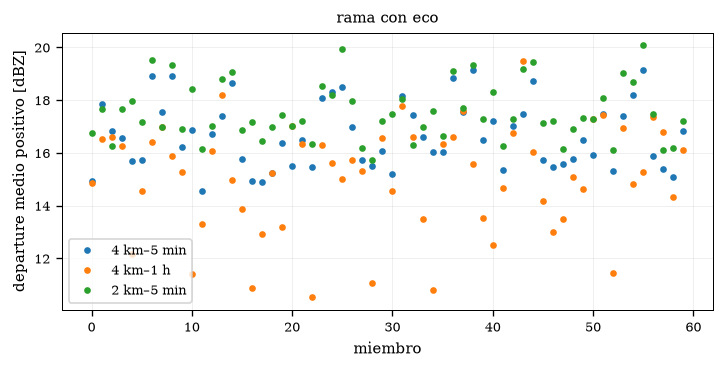

In [20]:
D2 = describe_csv(DERIVED / "N2" / "N2_departures.csv")
fig, ax = plt.subplots(figsize=(7, 3))
for ds, g in D2[D2.branch == "echo"].groupby("dataset"):
    ax.plot(g.member, g.pos_mean, "o", ms=3, label=nb.DS_LABEL.get(ds, ds))
ax.set(xlabel="miembro", ylabel="departure medio positivo [dBZ]", title="rama con eco")
ax.legend()
plt.show()

### 4.2 · N3

**`N3/N3_sums_runs.csv`** (`preflight`). Una fila = una corrida (dataset, hora): `tag`, `dataset_id` y cómo se comprobó (`id_source`: el `dataset_id` del archivo, o $h(\mathbf{x})$ de la verdad recalculado desde el subset, con su error `id_err_dbz` [dBZ]); `stride`, `ntemp`, `methods`, `n_files`, `Ne`, `R` [dBZ²], `dbz_min` [dBZ], `qualifies`.

**`N3/N3_sums_base.csv`** (`build`). Una fila = (dataset, hora, miembro verdad, esquema, variable), con `var` = `obs` (Z), una de las 8 de estado o `qtot` = $q_g+q_r+q_s$ (error = suma de los errores con signo de las tres especies). Las columnas de suma de arriba y `n_nan` (celdas con la variable no finita, fuera de las sumas). Para Z, $|e|$ es la columna `rmse_*_point_obs` del archivo; para el estado, media − verdad en float64. `scrps_*` y `ssp*` quedan vacías para `qtot`, que no tiene CRPS en los archivos.

data/derived/N3/N3_sums_runs.csv   0.0 MB, 12 filas × 14 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,21.000000,18
tag,str,12,NaN,NaN,WS_A_sweep_1800_LOC0.1_ALLMEM
dataset_id,str,3,NaN,NaN,A
id_source,str,2,NaN,NaN,H(x) del subset
id_err_dbz,float64,4,0.000002,0.000002,0.000002
stride,int64,1,10.000000,10.000000,10
ntemp,str,1,NaN,NaN,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
methods,str,1,NaN,NaN,"['TEnKF', 'AOEI']"
n_files,int64,1,60.000000,60.000000,60


data/derived/N3/N3_sums_base.csv   17.7 MB, 79,200 filas × 20 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,1.800000e+01,2.100000e+01,18
tm,int64,60,0.000000e+00,5.900000e+01,0
method,str,2,NaN,NaN,AOEI
ntemp,int64,10,1.000000e+00,1.000000e+01,1
var,str,10,NaN,NaN,obs
n,float64,567,3.568000e+03,3.292500e+04,8511.0
se2_f,float64,7200,1.157167e-07,2.971627e+08,202068.24188
se2_a,float64,79200,2.231840e-08,2.956331e+08,375140.186753
sae_f,float64,7200,6.076117e-03,2.260327e+06,20595.154353


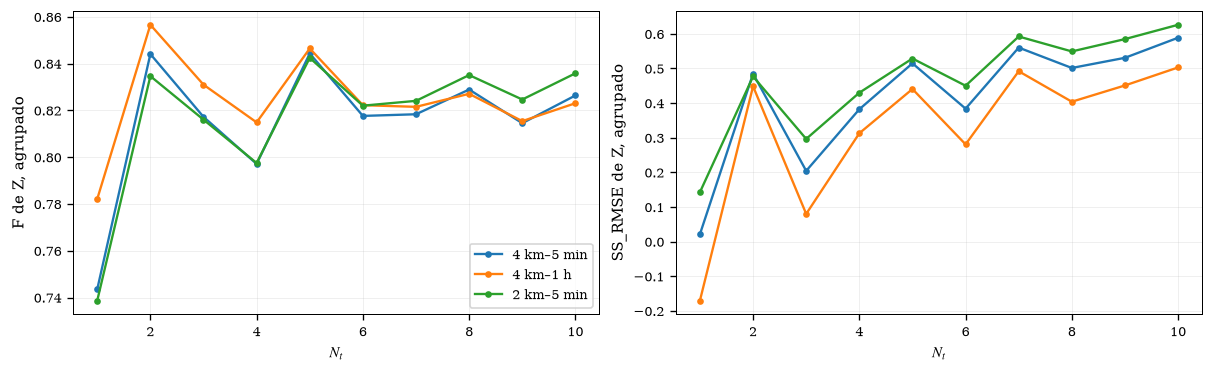

In [21]:
R3 = describe_csv(DERIVED / "N3" / "N3_sums_runs.csv")
B3 = describe_csv(DERIVED / "N3" / "N3_sums_base.csv")
z = B3[B3["var"] == "obs"].groupby(["dataset", "method", "ntemp"])[["se2_f", "se2_a", "n_change", "n_imp"]].sum()
z["F"] = z.n_imp / z.n_change
z["SS_RMSE"] = 1 - np.sqrt(z.se2_a / z.se2_f)
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ds, g in z.xs("TEnKF", level="method").groupby(level="dataset"):
    g = g.droplevel("dataset")
    ax[0].plot(g.index, g.F, "-o", ms=3, label=nb.DS_LABEL[ds])
    ax[1].plot(g.index, g.SS_RMSE, "-o", ms=3)
ax[0].set(xlabel="$N_t$", ylabel="F de Z, agrupado")
ax[1].set(xlabel="$N_t$", ylabel="SS_RMSE de Z, agrupado")
ax[0].legend()
plt.show()

**`N3/N3_sums_rule.csv`** (`build`). Lo mismo por regla de rechazo, una fila = (dataset, hora, miembro verdad, esquema, variable, regla). La regla rechaza la observación si `lo ≤ dep_b ≤ hi`: `none` (la población entera, igual a `N3_sums_base`), `d[0,10]`, `d[2,8]` [dBZ]. `n` cuenta las retenidas.

In [22]:
RU3 = describe_csv(DERIVED / "N3" / "N3_sums_rule.csv")
k = RU3[(RU3["var"] == "obs") & (RU3.method == "TEnKF") & (RU3.ntemp == 1)].groupby(["dataset", "rule"]).n.sum()
print("fracción retenida (Z, T1):")
display((k / k.xs("none", level="rule")).unstack("rule").rename(index=nb.DS_LABEL).round(3))

data/derived/N3/N3_sums_rule.csv   55.0 MB, 237,600 filas × 21 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,1.800000e+01,2.100000e+01,18
tm,int64,60,0.000000e+00,5.900000e+01,0
method,str,2,NaN,NaN,AOEI
ntemp,int64,10,1.000000e+00,1.000000e+01,1
var,str,10,NaN,NaN,obs
rule,str,3,NaN,NaN,none
n,float64,2050,2.210000e+03,3.292500e+04,8511.0
se2_f,float64,21600,8.959510e-08,2.971627e+08,202068.24188
se2_a,float64,237600,8.319335e-09,2.956331e+08,375140.186753


fracción retenida (Z, T1):


rule,"d[0,10]","d[2,8]",none
dataset,,,
4 km–5 min,0.719,0.906,1.0
4 km–1 h,0.640,0.879,1.0
2 km–5 min,0.745,0.911,1.0


**`N3/N3_sums_bins.csv`** (`build`). Una fila = un bin no vacío de un predictor, por (dataset, miembro verdad, esquema, variable ∈ `obs`, `w`, `qtot`), con las cuatro horas juntas. Predictores y bordes: `dep_b` = $d$ de −30 a 30 dBZ cada 2; `norm_innov` = $|d|/\sqrt{\sigma_f^2+R}$ de 0 a 6 cada 0,25; `n_active_f_point` ($N_{Z>0}$) en bins de un miembro. `bin_left`, `bin_right` y las sumas. N3 los agrupa en bins más gruesos para la figura 3; N4 usa los mismos bordes.

data/derived/N3/N3_sums_bins.csv   132.2 MB, 631,323 filas × 21 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
tm,int64,60,0.000000e+00,5.900000e+01,0
method,str,2,NaN,NaN,AOEI
ntemp,int64,10,1.000000e+00,1.000000e+01,1
var,str,3,NaN,NaN,obs
predictor,str,3,NaN,NaN,dep_b
bin_left,float64,104,-3.000000e+01,5.850000e+01,-26.0
bin_right,float64,105,-2.800000e+01,5.950000e+01,-24.0
n,float64,4375,1.000000e+00,6.145800e+04,2.0
se2_f,float64,57162,5.751968e-14,9.408511e+05,1215.564742


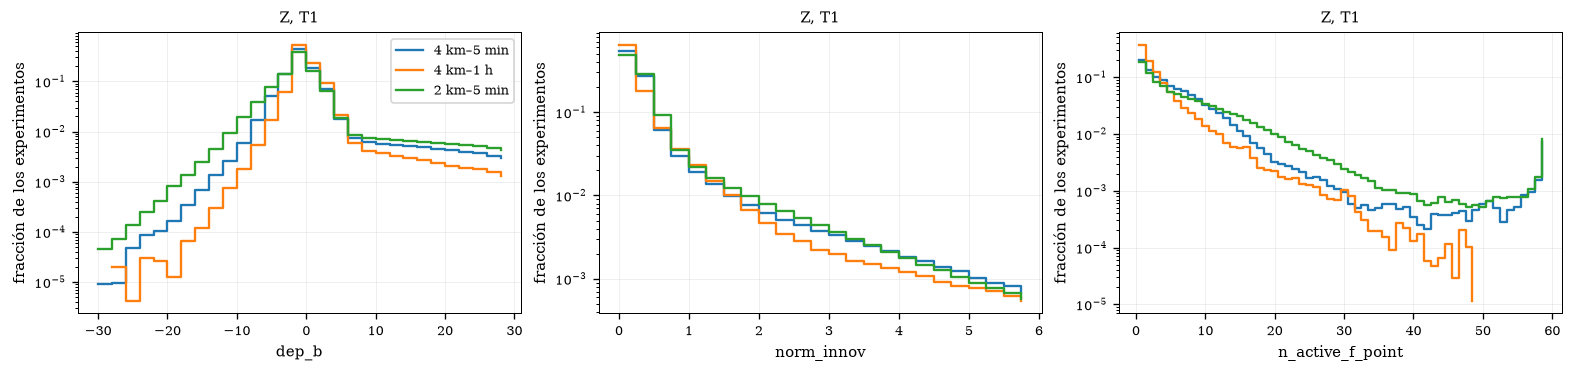

In [23]:
BI3 = describe_csv(DERIVED / "N3" / "N3_sums_bins.csv")
sel = BI3[(BI3["var"] == "obs") & (BI3.method == "TEnKF") & (BI3.ntemp == 1)]
fig, ax = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
for a, p in zip(ax, ("dep_b", "norm_innov", "n_active_f_point")):
    for ds, g in sel[sel.predictor == p].groupby("dataset"):
        c = g.groupby("bin_left").n.sum()
        a.step(c.index, c / c.sum(), where="post", label=nb.DS_LABEL[ds])
    a.set(xlabel=p, ylabel="fracción de los experimentos", yscale="log", title="Z, T1")
ax[0].legend()
plt.show()

**`N3/N3_sums_obs.csv`** (`build`). Una fila = (dataset, hora, miembro verdad): `n_points` (celdas observadas), `n_nan`, `n_echo` (verdad con eco, `yo_clean` > 0), `n_aoei` (`norm_innov` > 1, donde AOEI infla R), `n_echo_aoei`.

data/derived/N3/N3_sums_obs.csv   0.0 MB, 720 filas × 8 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.0,21.0,18
tm,int64,60,0.0,59.0,0
n_points,int64,468,3569.0,32925.0,8511
n_nan,int64,1,0.0,0.0,0
n_echo,int64,587,98.0,6431.0,513
n_aoei,int64,561,217.0,5096.0,565
n_echo_aoei,int64,573,44.0,4270.0,301


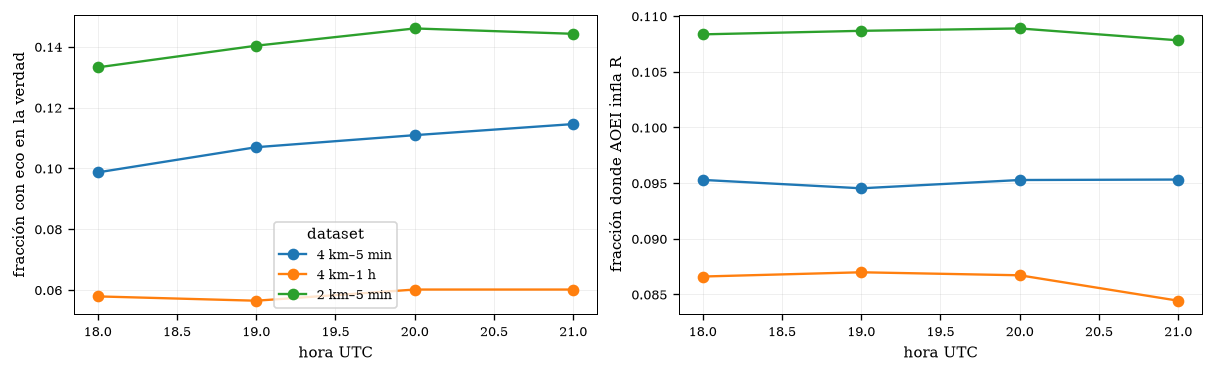

In [24]:
OB3 = describe_csv(DERIVED / "N3" / "N3_sums_obs.csv")
o = OB3.groupby(["dataset", "hour"])[["n_echo", "n_aoei", "n_points"]].sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
(o.n_echo / o.n_points).unstack("dataset").rename(columns=nb.DS_LABEL).plot(ax=ax[0], marker="o")
ax[0].set(xlabel="hora UTC", ylabel="fracción con eco en la verdad")
(o.n_aoei / o.n_points).unstack("dataset").plot(ax=ax[1], marker="o", legend=False)
ax[1].set(xlabel="hora UTC", ylabel="fracción donde AOEI infla R")
plt.show()

**El experimento de pesos** (`weights_preflight`, `build_weights`): A a las 19 UTC con α_s = 1 (`WS_A_sweep_1900_LOC0.1_ALLMEM`) y 0,25 (`…_AS0.25`).

- **`N3/N3_sums_weights_runs.csv`**: las dos corridas, una fila cada una, con su identidad y configuración; `weights_preflight` exige que difieran solo en α_s.
- **`N3/N3_sums_weights.csv`**: una fila = (α_s, miembro verdad, esquema, variable), con las sumas.
- **`N3/N3_sums_weights_split.csv`**: una fila = (α_s, miembro verdad, $N_t$ ∈ {3, 5}, mitad): Z con $|e_f|$ por debajo (`debajo`, ≤) o por encima (`encima`) de su mediana agrupada `median_ef` [dBZ].

data/derived/N3/N3_sums_weights_runs.csv   0.0 MB, 2 filas × 14 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
alpha_s,float64,2,0.250000,1.000000,1.0
tag,str,2,NaN,NaN,WS_A_sweep_1900_LOC0.1_ALLMEM
alpha_s_cfg,float64,2,0.250000,1.000000,1.0
dataset_id,str,1,NaN,NaN,NaN
id_source,str,2,NaN,NaN,H(x) del subset
id_err_dbz,float64,1,0.000002,0.000002,0.000002
n_files,int64,1,60.000000,60.000000,60
n_members,int64,1,60.000000,60.000000,60
stride,int64,1,10.000000,10.000000,10
loc_x,float64,1,0.100000,0.100000,0.1


data/derived/N3/N3_sums_weights.csv   2.9 MB, 13,200 filas × 19 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
alpha_s,float64,2,0.250000,1.000000e+00,1.0
tm,int64,60,0.000000,5.900000e+01,0
method,str,2,NaN,NaN,AOEI
ntemp,int64,10,1.000000,1.000000e+01,1
var,str,10,NaN,NaN,obs
n,float64,36,8944.000000,9.008000e+03,8969.0
se2_f,float64,600,0.000004,6.135045e+07,280121.681604
se2_a,float64,12000,0.000002,6.132317e+07,454401.842328
sae_f,float64,600,0.063865,5.635973e+05,24158.540015
sae_a,float64,12000,0.024613,5.643910e+05,32435.00361


data/derived/N3/N3_sums_weights_split.csv   0.1 MB, 480 filas × 21 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
alpha_s,float64,2,0.250000,1.000000,1.0
tm,int64,60,0.000000,59.000000,0
method,str,1,NaN,NaN,TEnKF
ntemp,int64,2,3.000000,5.000000,3
var,str,1,NaN,NaN,obs
half,str,2,NaN,NaN,debajo
median_ef,float64,1,1.276298,1.276298,1.276298
n,float64,80,4387.000000,4582.000000,4504.0
se2_f,float64,120,1716.395101,710282.639209,1810.4037
se2_a,float64,480,9164.397107,246882.876171,37339.509733


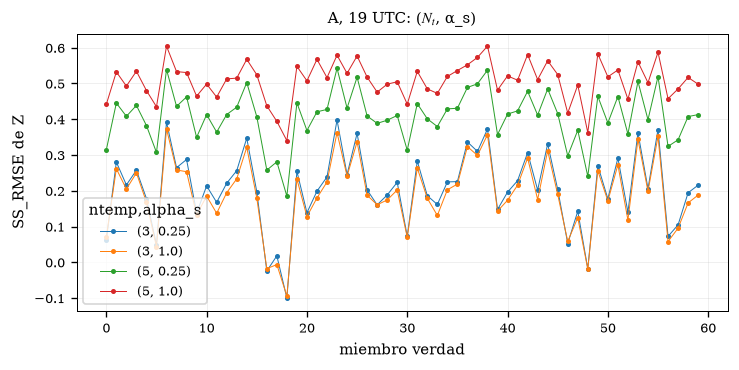

In [25]:
WR3 = describe_csv(DERIVED / "N3" / "N3_sums_weights_runs.csv")
WB3 = describe_csv(DERIVED / "N3" / "N3_sums_weights.csv")
WS3 = describe_csv(DERIVED / "N3" / "N3_sums_weights_split.csv")
w = WB3[(WB3["var"] == "obs") & (WB3.method == "TEnKF") & WB3.ntemp.isin([3, 5])]
w = w.assign(SS_RMSE=1 - np.sqrt(w.se2_a / w.se2_f))
ax = w.pivot_table(index="tm", columns=["ntemp", "alpha_s"], values="SS_RMSE").plot(
    figsize=(7, 3), marker="o", ms=2, lw=0.6)
ax.set(xlabel="miembro verdad", ylabel="SS_RMSE de Z", title="A, 19 UTC: ($N_t$, α_s)")
plt.show()

### 4.3 · N3, paso a paso

Los escribe `N3_Step_by_step.ipynb` (secciones 2 y 4), sobre A a las 20 UTC.

**`N3s/selection.csv`**. Los 60 puntos, 10 por condición (`core`, `edge`, `updraft`, `downdraft`, `weak`, `clear`, en el orden en que se eligen). Una fila = un punto (celda, miembro verdad): `condition`, `i`, `j`, `k`, `m` (el miembro verdad), `Z_t` [dBZ] y `w_t` [m/s] de la verdad en la celda, `n_echo` ($N_{Z>0}$ del prior), `prior_mean_Z` [dBZ] y la semilla `seed`.

**`N3s/steps/<condición>_<i>_<j>_<k>_tm<m>.npz`**. Un archivo por punto, con la observación asimilada por las funciones de actualización del runner y cada paso guardado:

- `xf_point` (59, 8): el prior de los 59 miembros en la celda; `hxf_point` (59,): su Z [dBZ]; `truth_point_state` (8,): la verdad; `yo`, `yo_clean` [dBZ].
- Dos corridas, con el prefijo `per_step/` (censura de hidrometeoros en cada paso, como el barrido) y `final/` (censura solo al final). En cada una:
  - vectores (6,), uno por esquema, con las columnas del barrido (sección 2) para esta celda;
  - por esquema `c{cc}` (cc = 00..05: TEnKF $N_t$ = 1..5 y AOEI; `c{cc}_method`, `c{cc}_ntemp`), con $N_t$ pasos: `c{cc}_steps_alpha` ($N_t$,) los pesos de los pasos; `c{cc}_steps_R_eff` el R efectivo [dBZ²]; `c{cc}_steps_dep` la innovación con que entra cada paso [dBZ]; `c{cc}_state_pre_clamp`, `c{cc}_state_post_clamp` ($N_t$, 59, 8) el ensamble a la salida de cada paso, antes y después de censurar; `c{cc}_hx` ($N_t$, 59) su Z; `c{cc}_trans` ($N_t$, 59, 59) y `c{cc}_transm` ($N_t$, 59) la matriz de transformación y los pesos de la media de la LETKF.

In [26]:
SEL = describe_csv(DERIVED / "N3s" / "selection.csv")
display(SEL.groupby("condition", sort=False).agg(puntos=("i", "size"), Z_t_mediana=("Z_t", "median"),
                                                  w_t_mediana=("w_t", "median"), N_Z_mediana=("n_echo", "median")))
r = SEL[SEL.condition == S_COND].iloc[0]
F_P = sorted((DERIVED / "N3s" / "steps").glob(f"{r.condition}_{r.i}_{r.j}_{r.k}_tm*.npz"))
assert len(F_P) == 1, F_P
F_P = F_P[0]
K_P = describe_npz(F_P, show=False)
print("claves del punto:")
display(K_P[~K_P.clave.str.contains("/")])
print("claves de un esquema (per_step/c04_ = TEnKF-T5):")
display(K_P[K_P.clave.str.startswith("per_step/c04_")])
vec = K_P.clave.str.match(r"^per_step/(?!c\d\d_)")
print(f"y {vec.sum()} vectores (6,) por corrida, uno por esquema; las mismas claves con el prefijo final/")

data/derived/N3s/selection.csv   0.0 MB, 60 filas × 11 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
condition,str,6,NaN,NaN,core
i,int64,37,3.400000e+01,3.000000e+02,180
j,int64,45,0.000000e+00,4.400000e+02,150
k,int64,11,0.000000e+00,1.000000e+01,2
m,int64,36,0.000000e+00,5.900000e+01,10
Z_t,float64,36,0.000000e+00,5.758439e+01,47.720932
w_t,float64,60,-1.169141e+01,2.418359e+01,-0.643799
n_echo,int64,22,1.000000e+00,5.900000e+01,25
prior_mean_Z,float64,60,3.954943e-02,4.577724e+01,11.737714
seed,int64,1,2.024032e+07,2.024032e+07,20240319


,puntos,Z_t_mediana,w_t_mediana,N_Z_mediana
condition,,,,
core,10,49.501869,-0.416489,10.5
edge,10,5.919288,0.044579,9.0
updraft,10,52.144894,18.320312,11.0
downdraft,10,49.368568,-8.727539,5.0
weak,10,0.000000,0.014903,3.5
clear,10,0.000000,-0.008818,3.5


data/derived/N3s/steps/core_180_150_2_tm10.npz   0.6 MB en disco, 895 claves
claves del punto:


,clave,forma,dtype,tamaño
0,xf_point,"(59, 8)",float32,0.0 MB
1,truth_point_state,"(8,)",float32,0.0 MB
2,hxf_point,"(59,)",float32,0.0 MB
3,yo,(),float32,0.0 MB
4,yo_clean,(),float32,0.0 MB


claves de un esquema (per_step/c04_ = TEnKF-T5):


,clave,forma,dtype,tamaño
422,per_step/c04_method,(),<U5,0.0 MB
423,per_step/c04_ntemp,(),int32,0.0 MB
424,per_step/c04_alpha_s,(),float32,0.0 MB
425,per_step/c04_lx_km,(),float32,0.0 MB
426,per_step/c04_ly_km,(),float32,0.0 MB
427,per_step/c04_lz_km,(),float32,0.0 MB
428,per_step/c04_steps_alpha,"(5,)",float32,0.0 MB
429,per_step/c04_steps_R_eff,"(5,)",float32,0.0 MB
430,per_step/c04_steps_dep,"(5,)",float32,0.0 MB
431,per_step/c04_state_pre_clamp,"(5, 59, 8)",float32,0.0 MB


y 361 vectores (6,) por corrida, uno por esquema; las mismas claves con el prefijo final/


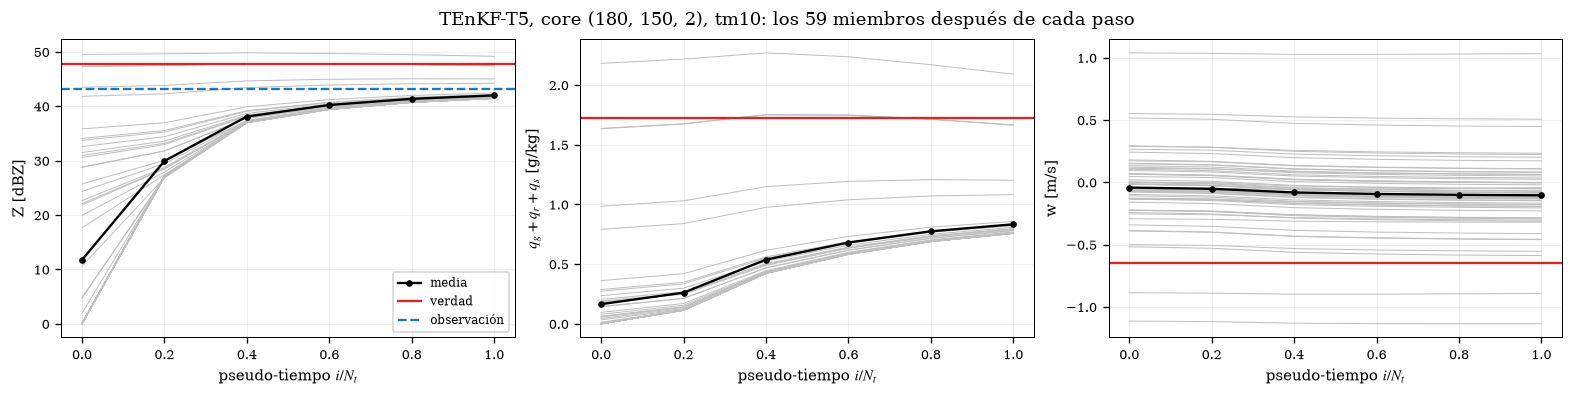

In [27]:
P = dict(np.load(F_P, allow_pickle=True))
run = "per_step"
cc = next(c for c in range(6) if str(P[f"{run}/c{c:02d}_method"]) == "TEnKF"
          and int(P[f"{run}/c{c:02d}_ntemp"]) == 5)
pre = f"{run}/c{cc:02d}_"
nt = int(P[pre + "ntemp"])
t = np.arange(nt + 1) / nt                     # pseudo-tiempo i/N_t
iq = [nb.VI[v] for v in nb.HYDRO]
X = np.concatenate([P["xf_point"][None], P[pre + "state_post_clamp"]]).astype(float)   # (Nt+1, 59, 8)
traj = {"Z [dBZ]": np.r_[P["hxf_point"][None], P[pre + "hx"]],
        "$q_g+q_r+q_s$ [g/kg]": X[..., iq].sum(-1) * 1e3,
        "w [m/s]": X[..., nb.VI["w"]]}
truth = {"Z [dBZ]": float(P["yo_clean"]),
         "$q_g+q_r+q_s$ [g/kg]": float(P["truth_point_state"][iq].sum()) * 1e3,
         "w [m/s]": float(P["truth_point_state"][nb.VI["w"]])}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), constrained_layout=True)
for a, (lab, v) in zip(ax, traj.items()):
    a.plot(t, v, color="0.75", lw=0.6)
    a.plot(t, v.mean(axis=1), "k-o", ms=3, label="media")
    a.axhline(truth[lab], color="C3", label="verdad")
    if lab.startswith("Z"):
        a.axhline(float(P["yo"]), color="C0", ls="--", label="observación")
    a.set(xlabel="pseudo-tiempo $i/N_t$", ylabel=lab)
ax[0].legend(fontsize=7)
fig.suptitle(f"TEnKF-T5, {r.condition} ({r.i}, {r.j}, {r.k}), tm{r.m:02d}: los 59 miembros después de cada paso")
plt.show()

### 4.4 · N4

**`N4/N4_runs.csv`** (`build`, sección 0 de N4). Una fila = una corrida REF (dataset, hora): `tag`, `R` [dBZ²], `dbz_min` [dBZ], `clamp`, `loc` [km], `n_files`, `storm_thresh` [dBZ].

**`N4/N4_nan_cells.csv`** (`masks_one`). Una fila = una celda de un subset con algún miembro no finito: (dataset, hora, i, j, k) y la lista de miembros rotos en `members`.

data/derived/N4/N4_runs.csv   0.0 MB, 12 filas × 9 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.0,21.0,18
tag,str,12,NaN,NaN,WS_A_multiobs_1800_LOC2.0_REF
R,float64,1,5.0,5.0,5.0
dbz_min,float64,1,0.0,0.0,0.0
clamp,str,1,NaN,NaN,per_step
loc,float64,1,2.0,2.0,2.0
n_files,int64,1,84.0,84.0,84
storm_thresh,float64,1,20.0,20.0,20.0


data/derived/N4/N4_nan_cells.csv   0.0 MB, 1,160 filas × 6 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.0,21.0,18
i,int64,440,0.0,556.0,3
j,int64,628,0.0,897.0,224
k,int64,11,0.0,10.0,6
members,str,62,NaN,NaN,38


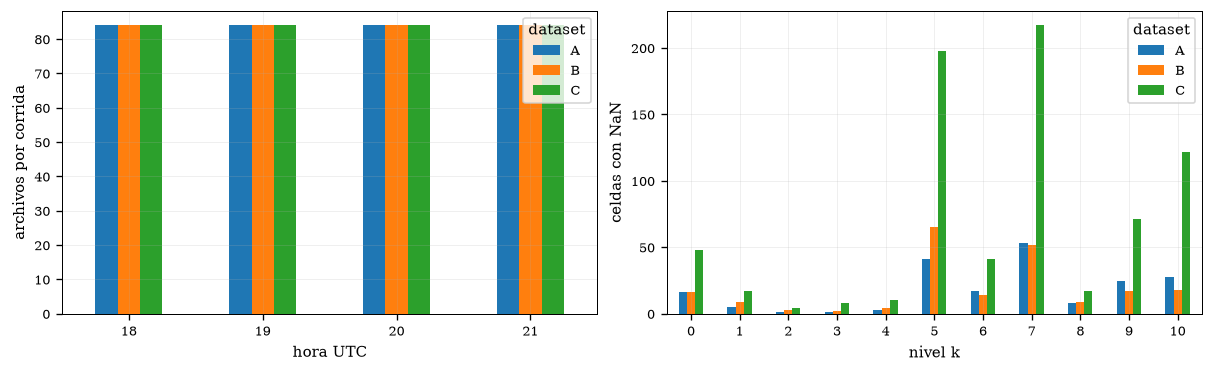

In [28]:
RU4 = describe_csv(DERIVED / "N4" / "N4_runs.csv")
NC4 = describe_csv(DERIVED / "N4" / "N4_nan_cells.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
RU4.pivot(index="hour", columns="dataset", values="n_files").plot.bar(ax=ax[0], rot=0)
ax[0].set(xlabel="hora UTC", ylabel="archivos por corrida")
NC4.groupby(["dataset", "k"]).size().unstack("dataset").plot.bar(ax=ax[1], rot=0)
ax[1].set(xlabel="nivel k", ylabel="celdas con NaN")
plt.show()

**`N4/N4_masks.csv`** (`masks_one`). Una fila = (dataset, hora, miembro verdad): `n_obs`, `n_cells`, `n_nan_cells`, `n_obs_on_nan`, `n_negq_outside`; por dominio (`alcanzadas`, `tormenta`, `observadas`): `n_reach_*` (celdas dentro del corte de la localización de alguna observación), `n_*` (las válidas: sin celdas NaN ni su vecindario), `n_nan_*`, `frac_near_*`, y `runner_touched_min_*`/`max_*` (lo que contó el runner, para el control).

data/derived/N4/N4_masks.csv   0.0 MB, 144 filas × 26 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,1.800000e+01,2.100000e+01,18
tm,int64,12,0.000000e+00,5.900000e+01,0
n_obs,int64,144,3.600060e+05,3.296852e+06,830985
n_cells,int64,2,1.523027e+06,5.511924e+06,1523027
n_nan_cells,int64,11,4.100000e+01,1.950000e+02,46
n_obs_on_nan,int64,16,6.000000e+00,9.900000e+01,19
n_negq_outside,int64,10,0.000000e+00,3.500000e+01,0
n_reach_alcanzadas,int64,144,9.517510e+05,5.000420e+06,1327382
n_alcanzadas,int64,144,9.510170e+05,4.975385e+06,1325772


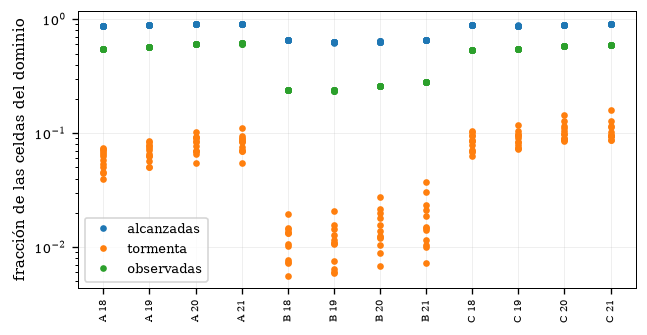

In [29]:
MA4 = describe_csv(DERIVED / "N4" / "N4_masks.csv")
fig, ax = plt.subplots(figsize=(6, 3))
for dn in ("alcanzadas", "tormenta", "observadas"):
    ax.plot(MA4.dataset + " " + MA4.hour.astype(str), MA4[f"n_{dn}"] / MA4.n_cells, "o", ms=3, label=dn)
ax.set(ylabel="fracción de las celdas del dominio", yscale="log")
ax.tick_params(axis="x", rotation=90, labelsize=6)
ax.legend()
plt.show()

**`N4/N4_ref_skill.csv`** (`skill_one`). Una fila = (dataset, miembro verdad, hora, esquema, dominio), con `hour` = `18`…`21` o `all` (las cuatro horas juntas). `n` (celdas válidas del dominio); conteos de la skill por celda (`n_improved`, `n_degraded`, `n_tie`) y `mean`, `median`, `median_changed` [dBZ]; y las sumas: `sum_err2_f`, `sum_err2_a` [dBZ²], `sum_crps_f`, `sum_crps_a` [dBZ], `sum_var_f`, `sum_var_a` [dBZ²] (dispersión²). En las filas `all` las sumas son la suma de las cuatro horas.

data/derived/N4/N4_ref_skill.csv   0.7 MB, 3,240 filas × 19 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
tm,int64,12,0.000000e+00,5.900000e+01,0
hour,str,5,NaN,NaN,18
method,str,2,NaN,NaN,TEnKF
ntemp,int64,5,1.000000e+00,5.000000e+00,1
domain,str,3,NaN,NaN,alcanzadas
n,int64,540,8.549000e+03,1.965441e+07,1325772
n_improved,int64,3216,3.926000e+03,1.124155e+07,484347
n_degraded,int64,3217,5.860000e+02,6.115979e+06,338636
n_tie,int64,3010,2.518000e+03,7.189241e+06,502789


etapa               prior  posterior T1
dataset domain                         
A       alcanzadas   5.31          6.83
        observadas   6.49          8.40
        tormenta    16.90         11.35
B       alcanzadas   2.98          4.31
        observadas   4.53          6.70
        tormenta    18.21         11.79
C       alcanzadas   6.29          7.95
        observadas   7.81          9.91
        tormenta    17.23         12.78

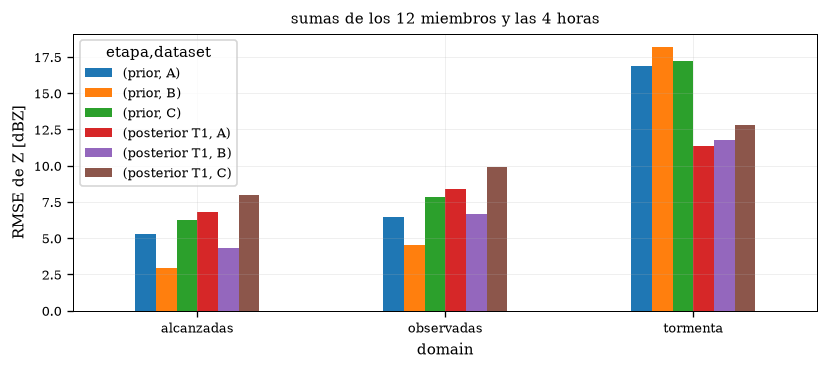

In [30]:
SK4 = describe_csv(DERIVED / "N4" / "N4_ref_skill.csv")
a = SK4[(SK4.hour == "all") & (SK4.method == "TEnKF") & (SK4.ntemp == 1)]
g = a.groupby(["dataset", "domain"])[["sum_err2_f", "sum_err2_a", "n"]].sum()
rmse = pd.DataFrame({"prior": np.sqrt(g.sum_err2_f / g.n), "posterior T1": np.sqrt(g.sum_err2_a / g.n)})
rmse.columns.name = "etapa"
display(rmse.round(2))
ax = rmse.unstack("dataset").plot.bar(figsize=(8, 3), rot=0)
ax.set(ylabel="RMSE de Z [dBZ]", title="sumas de los 12 miembros y las 4 horas")
plt.show()

**`N4/N4_scalars.csv`** (`skill_one`). Una fila = un archivo de esquema (dataset, hora, miembro verdad, esquema): todas sus claves escalares numéricas (925 columnas), con la gramática de la sección 3. Son sobre el dominio entero del runner.

data/derived/N4/N4_scalars.csv  864 filas × 925 columnas


,dataset,hour,tm,method,ntemp,alpha_s,lx_km,ly_km,lz_km,Ne,truth_member,store_ensemble
0,A,18,0,TEnKF,1,1.0,2.0,2.0,2.0,59,0,False
1,A,18,0,TEnKF,2,1.0,2.0,2.0,2.0,59,0,False
2,A,18,0,TEnKF,3,1.0,2.0,2.0,2.0,59,0,False


variable           P    T   qg   qr   qs  ref    u    v    w
metrica dominio                                             
bias    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
crps    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
kurt    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
rmse    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
skew    global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
spread  global   a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        obs      a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f
        storm    a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f  a,f

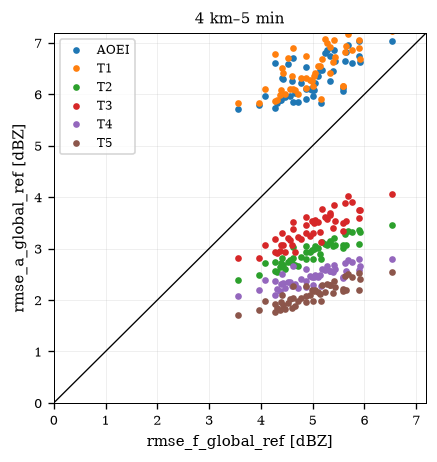

In [31]:
SC4 = pd.read_csv(DERIVED / "N4" / "N4_scalars.csv")
print(f"{ruta(DERIVED / 'N4' / 'N4_scalars.csv')}  {SC4.shape[0]} filas × {SC4.shape[1]} columnas")
display(SC4.iloc[:3, :12])
display(grammar(SC4.columns, r"^(?:n_)?(?P<metrica>rmse|bias|spread|crps|skew|kurt)_(?P<etapa>f|a)_"
                             r"(?P<dominio>global|storm|obs)_(?P<variable>\w+)$", ["metrica", "dominio"], ["variable"]))
x = SC4[SC4.dataset == DS]
fig, ax = plt.subplots(figsize=(4, 4))
for (m, nt), g in x.groupby(["method", "ntemp"]):
    ax.plot(g.rmse_f_global_ref, g.rmse_a_global_ref, "o", ms=3, label="AOEI" if m == "AOEI" else f"T{nt}")
lim = [0, x.rmse_f_global_ref.max() * 1.1]
ax.plot(lim, lim, "k", lw=0.8)
ax.set(xlim=lim, ylim=lim, xlabel="rmse_f_global_ref [dBZ]", ylabel="rmse_a_global_ref [dBZ]", title=nb.DS_LABEL[DS])
ax.legend(fontsize=7)
plt.show()

**`N4/N4_sums_spatial_A20.npz`** (`build_spatial`). A, 20 UTC. Dos rebanadas: el nivel `k` = 6 (5 km) con claves `map_*` (nx, ny) y la fila `j` = 180 (el corte de N2) con claves `sec_*` (nx, nz). `*_n_valid`: miembros verdad con la celda alcanzada y válida; `*_truth_mean`: media de la verdad [dBZ]; por esquema (TEnKF-T1, TEnKF-T2), las sumas sobre esos miembros: `*_se2_{f,a}_<esquema>`, `*_sae_{f,a}_<esquema>`, `*_n_change_<esquema>`, `*_n_imp_<esquema>`. Más `lats`, `lons`, `cut_lat`, `cut_lon`, `z_km`, `n_members` y los escalares del corte.

data/derived/N4/N4_sums_spatial_A20.npz   5.5 MB en disco, 39 claves


corte,map,sec
suma,,
n_change,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"
n_imp,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"
sae_a,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"
sae_f,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"
se2_a,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"
se2_f,"TEnKF-T1,TEnKF-T2","TEnKF-T1,TEnKF-T2"


{'dataset': 'A', 'hour': '20', 'k': 6, 'j': 180, 'z_map_km': 5.0, 'n_members': 12}


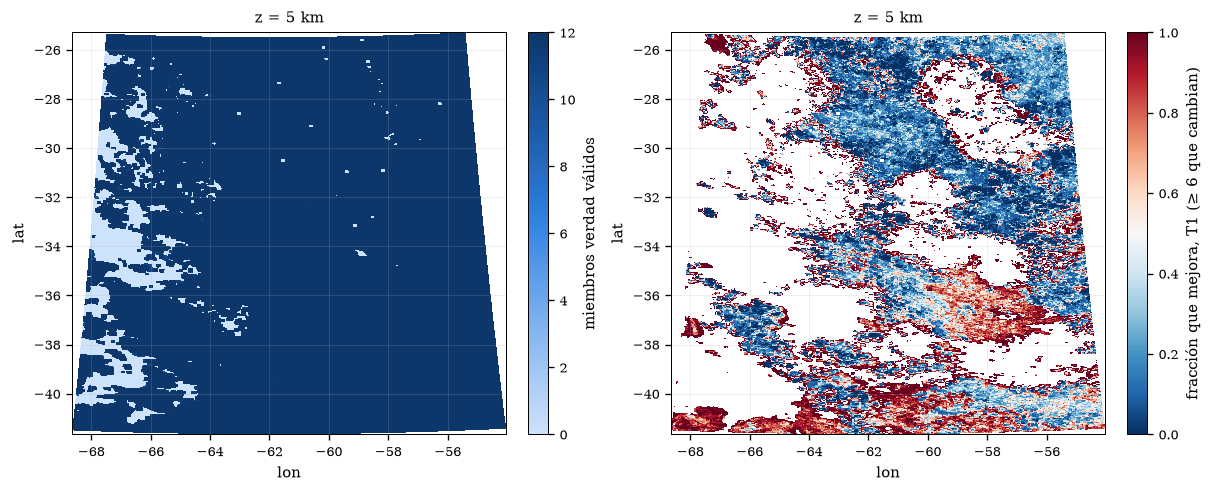

In [32]:
F = DERIVED / "N4" / "N4_sums_spatial_A20.npz"
K = describe_npz(F, show=False)
display(grammar(K.clave, r"^(?P<corte>map|sec)_(?P<suma>se2_f|se2_a|sae_f|sae_a|n_change|n_imp)_(?P<esquema>TEnKF-T\d+)$",
                ["suma"], ["corte"]))
SP4 = np.load(F)
print({k: SP4[k].item() for k in SP4.files if SP4[k].ndim == 0})
with np.errstate(invalid="ignore", divide="ignore"):
    F1 = np.where(SP4["map_n_change_TEnKF-T1"] >= 6,
                  SP4["map_n_imp_TEnKF-T1"] / SP4["map_n_change_TEnKF-T1"], np.nan)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
m = ax[0].pcolormesh(SP4["lons"], SP4["lats"], SP4["map_n_valid"].T, cmap=nb.CMAP_SEQ)
fig.colorbar(m, ax=ax[0], label="miembros verdad válidos")
m = ax[1].pcolormesh(SP4["lons"], SP4["lats"], F1.T, cmap=nb.CMAP_SKILL, vmin=0, vmax=1)
fig.colorbar(m, ax=ax[1], label="fracción que mejora, T1 (≥ 6 que cambian)")
for a in ax:
    a.set(xlabel="lon", ylabel="lat", title=f"z = {float(SP4['z_map_km']):g} km")
plt.show()

**`N4/N4_sums_pred.csv`** (`build_pred`). Como `N3_sums_bins`, para Z en las celdas observadas válidas de las corridas multi-obs: una fila = un bin no vacío por (dataset, miembro verdad, esquema ∈ T1, T2, predictor), con las cuatro horas juntas; mismos predictores y bordes que N3. Sumas `n`, `se2_*`, `sae_*`, `scrps_*`, `n_change`, `n_imp`.

data/derived/N4/N4_sums_pred.csv   1.4 MB, 8,126 filas × 16 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
tm,int64,12,0.000000,5.900000e+01,0
method,str,1,NaN,NaN,TEnKF
ntemp,int64,2,1.000000,2.000000e+00,1
predictor,str,3,NaN,NaN,dep_b
bin_left,float64,104,-30.000000,5.850000e+01,-30.0
bin_right,float64,105,-28.000000,5.950000e+01,-28.0
n,float64,3592,1.000000,6.082255e+06,40.0
se2_f,float64,4063,538.302989,7.507070e+07,33804.941541
se2_a,float64,8126,0.520478,5.165432e+08,8057.33456


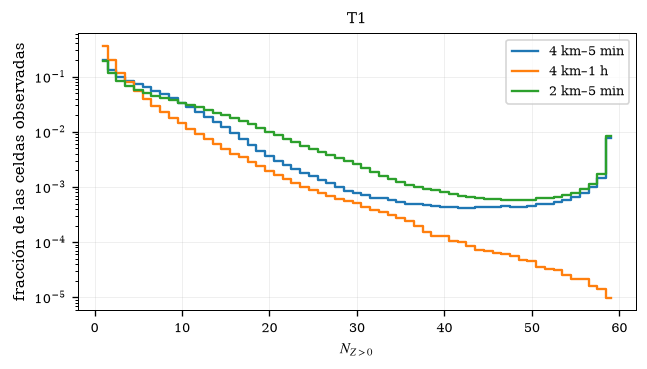

In [33]:
PC4 = describe_csv(DERIVED / "N4" / "N4_sums_pred.csv")
fig, ax = plt.subplots(figsize=(6, 3))
for ds, g in PC4[(PC4.predictor == "n_active_f_point") & (PC4.ntemp == 1)].groupby("dataset"):
    c = g.groupby("bin_left").n.sum()
    ax.step(c.index + 0.5, c / c.sum(), where="mid", label=nb.DS_LABEL[ds])
ax.set(xlabel="$N_{Z>0}$", ylabel="fracción de las celdas observadas", yscale="log", title="T1")
ax.legend()
plt.show()

**`N4/N4_innov_cross.csv`** (`build_nbr`). Una fila = (dataset, hora, miembro verdad, esquema ∈ T1, T2, tramo propio, tramo de los vecinos): `n`, `n_improved`, `n_degraded`. El tramo propio es el de la innovación de la celda observada; el de los vecinos, el de la media pesada con $\exp(-d^2/2)$ de las innovaciones de las otras observaciones dentro del corte. Tramos: `d < 0`, `[0, 10)`, `d ≥ 10` [dBZ] y `sin vecinos`.

**`N4/N4_innov_corr.csv`**: los momentos para la correlación entre las dos innovaciones, por (dataset, hora, tm, esquema): `n`, `sx`, `sy` [dBZ], `sxx`, `syy`, `sxy` [dBZ²].

data/derived/N4/N4_innov_cross.csv   0.2 MB, 3,200 filas × 10 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
propia,str,3,NaN,NaN,"[0, 10)"
vecinos,str,4,NaN,NaN,"[0, 10)"
n,int64,1296,1.0,1612314.0,509821
n_improved,int64,2428,0.0,1388048.0,367545
n_degraded,int64,2309,0.0,1085914.0,136827
dataset,str,3,NaN,NaN,C
hour,int64,4,18.0,21.0,18
tm,int64,12,0.0,59.0,0
method,str,1,NaN,NaN,TEnKF
ntemp,int64,2,1.0,2.0,1


data/derived/N4/N4_innov_corr.csv   0.0 MB, 288 filas × 11 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,C
hour,int64,4,1.800000e+01,2.100000e+01,18
tm,int64,12,0.000000e+00,5.900000e+01,0
method,str,1,NaN,NaN,TEnKF
ntemp,int64,2,1.000000e+00,2.000000e+00,1
n,int64,144,3.595120e+05,3.273439e+06,2984431
sx,float64,144,-1.065352e+06,5.685238e+06,-606135.10777
sy,float64,144,-1.114907e+06,5.663212e+06,-648343.089923
sxx,float64,144,3.779233e+06,3.143066e+08,127984212.248682
syy,float64,144,2.065580e+06,2.179712e+08,75030630.466791


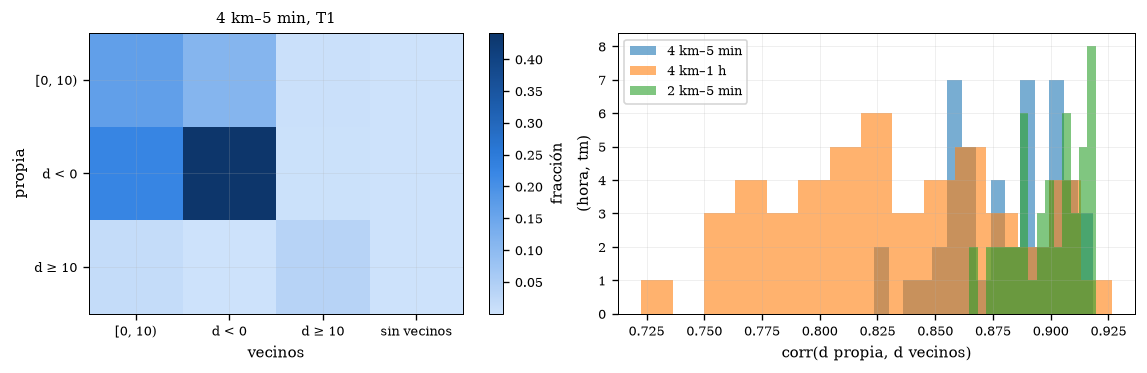

In [34]:
IX4 = describe_csv(DERIVED / "N4" / "N4_innov_cross.csv")
IC4 = describe_csv(DERIVED / "N4" / "N4_innov_corr.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
x = IX4[(IX4.dataset == DS) & (IX4.ntemp == 1)].groupby(["propia", "vecinos"]).n.sum().unstack()
m = ax[0].imshow(x.values / x.values.sum(), cmap=nb.CMAP_SEQ)
ax[0].set(xticks=range(x.shape[1]), xticklabels=x.columns, yticks=range(x.shape[0]), yticklabels=x.index,
          xlabel="vecinos", ylabel="propia", title=f"{nb.DS_LABEL[DS]}, T1")
fig.colorbar(m, ax=ax[0], label="fracción")
c = IC4[IC4.ntemp == 1]
r = (c.n * c.sxy - c.sx * c.sy) / np.sqrt((c.n * c.sxx - c.sx ** 2) * (c.n * c.syy - c.sy ** 2))
for ds, g in r.groupby(c.dataset):
    ax[1].hist(g, bins=15, alpha=0.6, label=nb.DS_LABEL[ds])
ax[1].set(xlabel="corr(d propia, d vecinos)", ylabel="(hora, tm)")
ax[1].legend()
plt.show()

**`N4/N4_state_prior.csv`** (`build_prior`). Una fila = (dataset, hora, tm, variable, `dominio`): `n`, `sum_err2` = Σ (media del prior − verdad)² en las unidades crudas al cuadrado. Dominios: `tormenta` y `aire claro` (celdas alcanzadas con y sin tormenta) y `completo` (el dominio entero, para el control contra el runner).

**`N4/N4_state_spread.csv`** (`build_spread`). Mismas claves: `sum_var_f` = Σ varianza del prior de los 59 miembros, desde el subset.

**`N4/N4_spread_check.csv`** (`build_spread`). El control del método con la reflectividad, por (dataset, hora, tm, esquema, `dom` ∈ global, storm): Σ varianza del prior desde el subset (`var_f_subset`) y desde los campos (`var_f_campos`); la del posterior por cancelación (`var_a_metodo`) y desde los campos (`var_a_campos`); ídem el MSE (`mse_a_*`) [dBZ²].

data/derived/N4/N4_state_prior.csv   0.2 MB, 3,456 filas × 7 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,2.100000e+01,18
tm,int64,12,0.000000,5.900000e+01,0
var,str,8,NaN,NaN,qg
dominio,str,3,NaN,NaN,tormenta
n,int64,299,8549.000000,5.511753e+06,68332
sum_err2,float64,3456,0.000004,3.288508e+10,0.001535


data/derived/N4/N4_state_spread.csv   0.2 MB, 3,456 filas × 7 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,2.100000e+01,18
tm,int64,12,0.000000,5.900000e+01,0
var,str,8,NaN,NaN,qg
dominio,str,3,NaN,NaN,tormenta
n,int64,315,8549.000000,5.511761e+06,68332
sum_var_f,float64,3456,0.000006,2.023578e+10,0.002306


data/derived/N4/N4_spread_check.csv   0.2 MB, 1,728 filas × 12 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,2.100000e+01,18
tm,int64,12,0.000000,5.900000e+01,0
method,str,2,NaN,NaN,TEnKF
ntemp,int64,5,1.000000,5.000000e+00,1
dom,str,2,NaN,NaN,global
var_f_subset,float64,288,261471.206171,2.293553e+08,38345412.983904
var_f_campos,float64,288,261471.206077,2.293553e+08,38345412.991176
var_a_metodo,float64,1728,13639.786476,8.740619e+07,15860986.110388
var_a_campos,float64,1728,13639.786382,8.740619e+07,15860986.11766


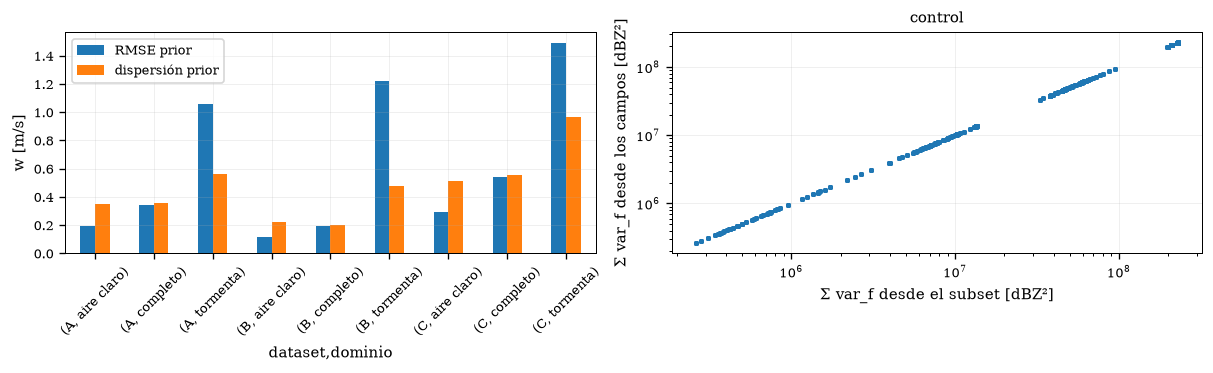

In [35]:
PR4 = describe_csv(DERIVED / "N4" / "N4_state_prior.csv")
SS4 = describe_csv(DERIVED / "N4" / "N4_state_spread.csv")
CH4 = describe_csv(DERIVED / "N4" / "N4_spread_check.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
key = ["dataset", "var", "dominio"]
e = PR4.groupby(key)[["sum_err2", "n"]].sum()
s = SS4.groupby(key)[["sum_var_f", "n"]].sum()
w = pd.DataFrame({"RMSE prior": np.sqrt(e.sum_err2 / e.n), "dispersión prior": np.sqrt(s.sum_var_f / s.n)}).xs("w", level="var")
w.plot.bar(ax=ax[0], rot=45)
ax[0].set(ylabel="w [m/s]")
ax[1].loglog(CH4.var_f_subset, CH4.var_f_campos, "o", ms=2)
ax[1].set(xlabel="Σ var_f desde el subset [dBZ²]", ylabel="Σ var_f desde los campos [dBZ²]", title="control")
plt.show()

**`N4/N4_state_crps.csv`** (`build_crps`). Mismas claves que `N4_state_prior`: `sum_crps_f` = $\sum$ CRPS del prior (los 59 miembros contra la verdad) en las unidades crudas, desde los subsets. El CRPS del posterior no se guarda por celda: N4 lo obtiene por cancelación con los totales por dominio del runner.

**`N4/N4_crps_check.csv`** (`build_crps`). El control de ese método con la reflectividad, que sí tiene campos de CRPS, por (dataset, hora, tm, esquema, `dom` ∈ global, storm): celdas (`n_subset`, `n_campos`), CRPS del prior desde el subset y desde los campos (`crps_f_subset`, `crps_f_campos`), y del posterior por cancelación y desde los campos (`crps_a_metodo`, `crps_a_campos`) [dBZ].

data/derived/N4/N4_state_crps.csv   0.2 MB, 3,888 filas × 7 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,2.100000e+01,18
tm,int64,12,0.000000,5.900000e+01,0
var,str,9,NaN,NaN,qg
dominio,str,3,NaN,NaN,tormenta
n,int64,556,8549.000000,5.511924e+06,68332
sum_crps_f,float64,3888,0.024865,2.240345e+08,1.255949


data/derived/N4/N4_crps_check.csv   0.2 MB, 1,728 filas × 12 columnas


,dtype,distintos,mín,máx,ejemplo (fila 0)
dataset,str,3,NaN,NaN,A
hour,int64,4,18.000000,2.100000e+01,18
tm,int64,12,0.000000,5.900000e+01,0
method,str,2,NaN,NaN,TEnKF
ntemp,int64,5,1.000000,5.000000e+00,1
dom,str,2,NaN,NaN,global
n_subset,int64,288,8549.000000,5.000420e+06,1327382
n_campos,int64,288,8549.000000,5.000420e+06,1327382
crps_f_subset,float64,288,80352.586593,1.075125e+07,780957.931443
crps_f_campos,float64,288,80352.586602,1.075125e+07,780957.931502


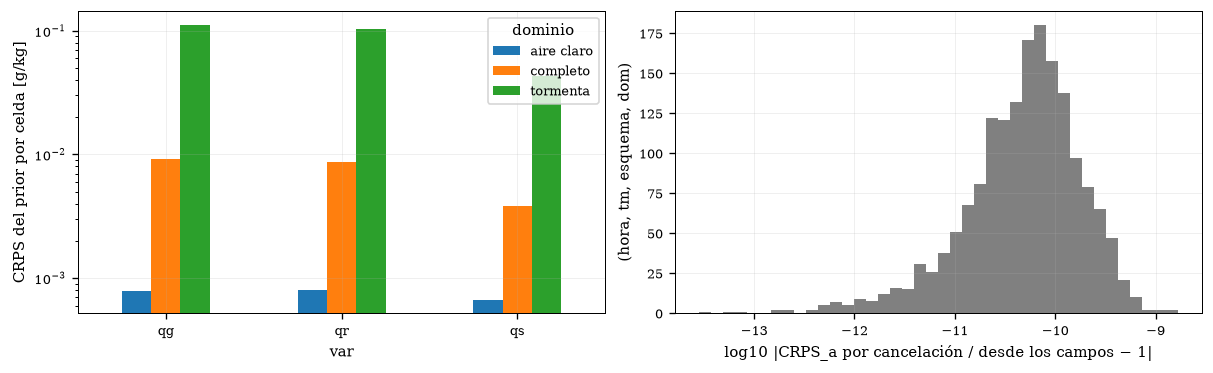

In [36]:
CR4 = describe_csv(DERIVED / "N4" / "N4_state_crps.csv")
CC4 = describe_csv(DERIVED / "N4" / "N4_crps_check.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
c = CR4.groupby(["var", "dominio"])[["sum_crps_f", "n"]].sum()
(c.sum_crps_f / c.n).unstack("dominio").loc[list(nb.HYDRO)].mul(1e3).plot.bar(ax=ax[0], rot=0)
ax[0].set(ylabel="CRPS del prior por celda [g/kg]", yscale="log")
rel = (CC4.crps_a_metodo / CC4.crps_a_campos - 1).abs()
ax[1].hist(np.log10(rel[rel > 0]), bins=40, color="0.5")
ax[1].set(xlabel="log10 |CRPS_a por cancelación / desde los campos − 1|", ylabel="(hora, tm, esquema, dom)")
plt.show()

## 5 · Orden del procesamiento

Cada notebook empieza con una sección 0 de postprocesado, controlada por `REBUILD`. Con `REBUILD = False` y los intermedios presentes, solo los carga; si falta alguno o `REBUILD = True`, lo reconstruye desde los archivos crudos y corre su `verify`. Las celdas de análisis calculan los números desde los intermedios; las de figura solo dibujan y guardan cada figura dos veces con `nb.save`, `figures/es/<stem>.png` y `figures/en/<stem>.png`.

### N0 · metodología

`N0_Methods_figures.ipynb` no lee datos: dibuja `tempering_schedule` con la fórmula de `tempering_schedule` de `src/da/core.py`.

### N2 · el prior

1. `build()`: para cada dataset (A, B, C) y hora (18–21) abre `3D_subsets_{ds}/subset_{ds}_…npz` **una vez** (`fields_3d`: carga el ensamble, aplica `nb.hx` por bloques de columnas y calcula media, dispersión, $N_{Z>0}$, asimetría y curtosis de Z, $q_g+q_r+q_s$ y w con los 59 miembros sin el miembro verdad 0, el histograma y los *departures* de los 60). Reduce a columnas y escribe `N2_maps.npz`, `N2_state.npz`, `N2_section.npz` (A, j = 180), `N2_hist.csv`, `N2_profiles.csv`, `N2_departures.csv` y `N2_scalars.csv`.
2. `verify()`: $N_{Z>0} \le 59$, la rama sin eco sin *departures* positivos, y que las ramas particionen los puntos.
3. Las figuras `N2_fig1a`…`N2_fig6d`.

### N3 · observación única

1. `preflight()`: por dataset y hora, la identidad de la corrida (config → subset usado → `dataset_id`, o $h(\mathbf{x})$ de la verdad recalculado desde el subset) y que tenga $N_t$ = 1..10 con `stride` 10 → `N3_sums_runs.csv`.
2. `build()`: para cada dataset y miembro verdad lee las cuatro horas de `WS_{ds}_sweep_{hh}00_LOC0.1_ALLMEM/…_tm{tm}.npz` (solo las columnas necesarias), calcula el error de cada variable y los predictores, y acumula las sumas por (hora, esquema, variable), por regla y por bin → `N3_sums_base`, `N3_sums_rule`, `N3_sums_bins`, `N3_sums_obs`; luego `verify()`.
3. `weights_preflight()`, `build_weights()`: `WS_A_sweep_1900_LOC0.1_ALLMEM` y `…_AS0.25` → `N3_sums_weights_runs`, `N3_sums_weights`, `N3_sums_weights_split`; luego `verify_weights()`.
4. Las tablas y las figuras `N3_fig1_headline`…`N3_fig7_weights`.

### N3 · paso a paso

`N3_Step_by_step.ipynb`, sobre A a las 20 UTC:

1. Clasifica todos los pares (celda, miembro verdad) del subset por la Z y la w de la verdad, y elige 10 puntos por condición con semilla fija → `N3s/selection.csv`.
2. Reproduce la observación de cada punto con el ruido de las corridas de observación única y vuelve a asimilarla con las funciones de actualización del runner (`src/da/`), con censura en cada paso y al final → `N3s/steps/*.npz`.
3. Verifica que la censura en cada paso reproduzca el barrido `WS_A_sweep_2000_LOC0.1_ALLMEM` en la misma celda y miembro verdad.
4. Las figuras `N3s/points/<condición>/…` y `N3s/<condición>_summary`, y las tablas.

### N4 · observaciones múltiples

Lee `WS_{ds}_multiobs_{hh}00_LOC2.0_REF` (A, B, C × 18–21; 12 miembros verdad × 6 esquemas + `ref`) y los subsets, en serie (`PARALLEL = False`, por `spawn` en macOS):

1. `masks_one` por (dataset, hora): abre el subset, censa sus celdas NaN y reconstruye por geometría las celdas alcanzadas (corte de la localización), los dominios (`nb.domain_masks`) y las exclusiones → `N4_nan_cells`, `N4_masks`.
2. `skill_one` por (dataset, miembro verdad): las cuatro horas y los seis esquemas sobre los campos 3D, por dominio → `N4_runs`, `N4_ref_skill`, `N4_scalars`; `verify()` contrasta con los escalares del runner.
3. Pasadas siguientes, cada una con su `verify_*`: `build_spatial` → `N4_sums_spatial_A20.npz`; `build_pred` → `N4_sums_pred`; `build_nbr` → `N4_innov_cross`, `N4_innov_corr`; `build_prior` → `N4_state_prior`; `build_spread` → `N4_state_spread`, `N4_spread_check`; `build_crps` → `N4_state_crps`, `N4_crps_check`.
4. Las tablas y las figuras `N4_fig1_seleccion`…`N4_fig7_dispersion`. Lee además `N2/N2_departures.csv` (la física de cada miembro) y `N3/N3_sums_base.csv`, `N3/N3_sums_bins.csv` (la referencia de observación única con los mismos 12 miembros verdad).